# MAKRO 2026 in ModelFlow: all of DREAM's standard shocks

This notebook solves every standard shock DREAM has published a solution for, and compares

- the shocks with each other, by groups of variables (headline, public finances, balance of payments, ...), and
- each ModelFlow solution with DREAM's own GAMS solution.

The shocks are permanent and unfinanced, from 2030, solved for the whole horizon 2030-2129. They come from
`MAKRO_src\Analysis\Standard_shocks\standard_shocks.gms`; `tools\dream_shocks.py` has them translated.

**Running it**

- The notebook stands alone: it starts from the model and the baseline (`data\makro26_baseline.pcimz`), solves
  all eleven shocks and writes `data\makro26_shocks.pcimz` with all the solutions (section 8). It does not read
  that file. The analysis of the solutions needs no solving: load `makro26_shocks.pcimz`
  (`makro26_io_shock.ipynb` and `makro26_shocks_report.ipynb` do).
- With the solve options saved with the model (faster factorization, linear solves refined to 1e-6) and the
  equations compiled with numba, the first shock takes 1-2 minutes (the factorization), the others about half a
  minute; public investment needs new derivatives in its last step (section 4), 1.6 minutes, and is solved last
  so no other shock has to recalculate them. All eleven took 7.8 minutes of solving on 2026-11-23 (10.4 with
  public investment in alphabetical order, 13 on 2026-11-20, 45 before); about 25 GB of memory on 2026-11-20.
  The first run on a new machine also compiles the equations (about 20 minutes, saved in `modelsource\`).
- It needs ModelFlow from `C:\modelflow2\modelflow` and the package `pypardiso` with oneMKL 2026 (both in
  `book314b`).

`makro26_experiment.ipynb` runs a single experiment, also one of your own.

In [1]:
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import modelclass
from modelclass import model
sys.path.insert(0, r'C:\mfmodeller_raw\makro\makro26\tools')
import dream_shocks, makro_groups
pd.set_option('display.max_colwidth', 120, 'display.max_rows', 200)
print('ModelFlow from', modelclass.__file__)

ModelFlow from c:\modelflow2\modelflow\modelclass.py


## 1. The model and the baseline

`data\makro26_baseline.pcimz` holds the model, the baseline, the descriptions, the derivative expressions and the
solve options (`tools\save_pcim.py` writes it; this notebook only reads it). It was saved from a model loaded with
`straight=True`, and the load does the same: the equations stay in the order of the file and the analysis of the
simultaneous structure is skipped. That analysis takes two minutes for MAKRO (`makro26_profile_load.ipynb`) and the
stacked Newton does not use it: it makes its own split. So the load takes a few seconds and needs only the file
name. Add `straight=False` to the call if you want to use the solvers that work period by period (`sim`,
`newton_ng`).

In [2]:
mmakro, baseline = model.modelload(r'C:\mfmodeller_raw\makro\makro26\data\makro26_baseline.pcimz')
print('Solve options saved with the model:', mmakro.oldkwargs)
inputs, solved = dream_shocks.model_variables(mmakro)
print(f'{len(solved):,} variables determined by the model, {len(inputs):,} inputs')

Feather/zip file read: C:\mfmodeller_raw\makro\makro26\data\makro26_baseline.pcimz


Model: MAKRO 2026-September (DREAM) in ModelFlow, baseline
Solve options saved with the model: {'solver': 'newtonstack_ng', 'forcenum': False, 'factorizer': {'method': 'normal', 'iparm': {'1': 13}, 'refine_tol': 1e-06}, 'silent': 1}
20,474 variables determined by the model, 16,531 inputs


## 2. Variable groups

The groups are defined in `tools\makro_groups.py`. Each variable has a label and a way to measure the effect:

| Effect measured in | Meaning |
| --- | --- |
| per cent | per cent difference from the baseline |
| per cent of real GDP | difference in per cent of baseline real GDP (the contribution to GDP) |
| per cent of GDP | difference in per cent of baseline nominal GDP (balances, stocks) |
| percentage points | difference of a rate |
| level | difference in the unit of the variable (1000 persons) |

The groups are also added to the model as ModelFlow variable groups, so `mmakro['#Public_finances']` works.

In [3]:
print(makro_groups.add_to_model(mmakro))
makro_groups.overview()

['Headline', 'Demand_contribution_to_GDP', 'Prices_and_wages', 'Labour_market', 'Public_finances', 'Balance_of_payments', 'Net_lending_by_sector', 'Value_added_by_sector', 'Investment_and_capital', 'Private_production', 'Exports_by_group', 'Households']


Variable  \
Group                       Label                                                            
Headline                    GDP                                                       QBNP   
                            Private consumption                                   QC__CTOT   
                            Public consumption                                    QG__GTOT   
                            Investment                                            QI__ITOT   
                            Exports                                               QX__XTOT   
                            Imports                                                QM__TOT   
                            Employment                                             NL__TOT   
                            Hourly wage                                                VHW   
                            Consumer prices                                       PC__CTOT   
Demand, contribution to GDP GDP                                                       QBNP   
                            Private consumption                                   QC__CTOT   
                            Public consumption                                    QG__GTOT   
                            Investment                                            QI__ITOT   
                            Exports                                               QX__XTOT   
                            Imports                                                QM__TOT   
Prices and wages            GDP deflator                                              PBNP   
                            Consumer prices                                       PC__CTOT   
                            Public consumption deflator                           PG__GTOT   
                            Investment deflator                                   PI__ITOT   
                            Export deflator                                       PX__XTOT   
                            Import deflator                                        PM__TOT   
                            Output price, private sector                         PY__SPTOT   
                            Hourly wage                                                VHW   
                            House price                                             PBOLIG   
Labour market               Employment, 1000 persons                               NL__TOT   
                            Hours worked                                           HL__TOT   
                            Net labour force, 1000 persons                    NNETTOARBSTY   
                            Net unemployment, 1000 persons                     NNETTOLEDIG   
                            Net unemployment rate                              RNETTOLEDIG   
                            Gross unemployment rate                           RBRUTTOLEDIG   
                            Wage per efficiency unit                                    PW   
                            User cost of labour, private sector                  PL__SPTOT   
Public finances             Budget balance                                          VSALDO   
                            Primary balance                                     VPRIMSALDO   
                            Primary revenue                                    VOFFPRIMIND   
                            Primary expenditure                                 VOFFPRIMUD   
                            Direct taxes                                         VTDIREKTE   
                            Indirect taxes                                     VTINDIREKTE   
                            Public consumption, nominal                           VG__GTOT   
                            Social transfers                                     VOVF__TOT   
                            Net interest income                              VOFFNETRENTER   
                            Net financia

## 3. The shocks

In [4]:
first, last = 2030, 2129
shocks = dream_shocks.shock_names()             # all shocks with a solution from DREAM
# public investment last: it leaves derivatives from another point stored, and the next shock would have to
# recalculate them at its start
shocks = sorted(shocks, key=lambda n: n == 'Offentlige_investeringer')
table_years = [2030, 2035, 2129]                # first year, after five years, long run

# The solve options: dream_shocks solves with the options saved with the model (the stacked Newton, exact
# derivatives, the faster PARDISO factorization of oneMKL 2026 with linear solves refined to 1e-6) and adds
# ljit=True (the equations compiled with numba). Options given to run_standard_shock replace them.

label = dream_shocks.SHORT
pd.DataFrame({'Label': {n: label[n] for n in shocks},
              'What DREAM changes': {n: dream_shocks.DESCRIPTION.get(n, '') for n in shocks}})

,Label,What DREAM changes
ArbejdsProd,Labour productivity,"Labour productivity (qProdHh_t, qProdxDK) up 1 per cent"
Arbejdsudbud_beskaeftigelse,Labour supply,Structural employment (snLHh[a]) up 1 per cent; the participation parameter uDeltag is freed
Eksportmarkedsvaekst,Export market,"Export market (uXMarked) up, 1 per cent of GDP"
Importpris,Import prices,Import prices (pM[s]) up 1 per cent
KapitalProd,Capital productivity,"Capital productivity (uK[iM,sp], uK[iB,sp]) up 1 per cent"
Offentlig_Beskaeftigelse,Public employment,Public employment (hL[off]) up by 1 per cent of GDP
Offentlig_varekoeb,Public purchases,Public purchases of goods and services (qR[off]) up by 1 per cent of GDP
Overforsel_privat,Transfers to households,Lump sum transfer to households (vOffTilHhRest) of 1 per cent of GDP
Rente,Interest rate,ECB interest rate (rRenteECB) up 1 percentage point
Udenlandske_priser,Foreign prices,Import prices (pM[s]) and export-competing foreign prices (pXUdl[x]) up 1 per cent


## 4. Solve

Each shock is solved in two steps as DREAM does (1 per cent of the shock, scaled up, then the whole shock), every
equation is evaluated on the solution, and the solution is compared with DREAM's for all 20 474 variables.
The whole solutions are kept in memory (about 37 MB each) for section 8.

The whole shock starts on the stored factorization (the derivatives of the baseline). If the largest residual
grows in one of the first three iterations, the step starts again from the same point with the derivatives
recalculated there (one factorization) and goes on with them. Of the eleven shocks only public investment (+28
per cent on public investment) needs it. It is solved last (section 3): a shock after it would have to recalculate
the derivatives at its start, about a minute. If that fails too, a careful last attempt goes through 1 and 30 per
cent of the shock.

A shock that still fails is reported and left out of the comparisons and of the file written in section 8. The
cell ends with the time of every shock and the total.

In [5]:
keep = makro_groups.group_variables()
solutions, mf, dr, stats = {}, {}, {}, {}      # whole solutions, group variables, DREAM's group variables, checks

t_start = time.time()
for name in shocks:
    t_shock = time.time()
    try:
        full, dream, st = dream_shocks.run_standard_shock(mmakro, baseline, name, first, last)
    except Exception as e:
        stats[name] = {'status': f'failed: {type(e).__name__}: {str(e)[:120]}',
                       'minutes': round((time.time() - t_shock) / 60, 1)}
        print(f'{name:28} FAILED after {stats[name]["minutes"]:.1f} min {type(e).__name__}: {str(e)[:200]}', flush=True)
        continue
    ok = st['missing values'] == 0 and st['equation error'] < 1e-4
    stats[name] = {'status': 'ok' if ok else 'not solved', **st}
    if ok:
        solutions[name] = full
        mf[name] = full[keep]
        if dream is not None:
            dr[name] = dream[keep].copy()
    print(f"{name:28} {stats[name]['status']:10} solved in {st['minutes']:4.1f} min  equation error {st['equation error']:.1e}"
          f"  largest difference from DREAM {st.get('largest difference from DREAM', float('nan')):.1e}", flush=True)
    del full, dream
solve_minutes = (time.time() - t_start) / 60
solved_shocks = [n for n in dream_shocks.shock_names() if n in mf]      # in DREAM's order

# timing of every shock, in the order solved
timing = pd.DataFrame({'Shock': [label[n] for n in shocks],
                       'Status': [stats[n]['status'] for n in shocks],
                       'Minutes': [stats[n].get('minutes', float('nan')) for n in shocks]}, index=shocks)
print(f'\n{len(solved_shocks)} of {len(shocks)} shocks solved, {solve_minutes:.1f} minutes in all')
display(timing.style.format({'Minutes': '{:.1f}'}))

ArbejdsProd                  ok         solved in  1.5 min  equation error 7.2e-10  largest difference from DREAM 4.4e-05


Arbejdsudbud_beskaeftigelse  ok         solved in  0.5 min  equation error 6.4e-08  largest difference from DREAM 3.4e-05


Eksportmarkedsvaekst         ok         solved in  0.4 min  equation error 2.6e-09  largest difference from DREAM 4.4e-05


Importpris                   ok         solved in  0.4 min  equation error 1.1e-07  largest difference from DREAM 4.0e-05


KapitalProd                  ok         solved in  0.4 min  equation error 1.4e-08  largest difference from DREAM 4.7e-05


Offentlig_Beskaeftigelse     ok         solved in  0.6 min  equation error 2.3e-06  largest difference from DREAM 4.4e-05


... (3 outputs left out)

Udenlandske_priser           ok         solved in  0.4 min  equation error 2.6e-08  largest difference from DREAM 3.7e-05


Offentlige_investeringer     ok         solved in  1.4 min  equation error 4.2e-08  largest difference from DREAM 3.9e-05



11 of 11 shocks solved, 7.7 minutes in all


,Shock,Status,Minutes
ArbejdsProd,Labour productivity,ok,1.5
Arbejdsudbud_beskaeftigelse,Labour supply,ok,0.5
Eksportmarkedsvaekst,Export market,ok,0.4
Importpris,Import prices,ok,0.4
KapitalProd,Capital productivity,ok,0.4
Offentlig_Beskaeftigelse,Public employment,ok,0.6
Offentlig_varekoeb,Public purchases,ok,0.5
Overforsel_privat,Transfers to households,ok,0.5
Rente,Interest rate,ok,0.7
Udenlandske_priser,Foreign prices,ok,0.4


## 5. The solutions against DREAM

- **equation error**: the largest error of any equation on the ModelFlow solution.
- **largest difference from DREAM**: over all variables and years, relative to the size of the variable (the
  larger of the baseline and DREAM's value; variables that are practically zero are measured against 1e-6).
- **The first year.** In GAMS a few equations are left out in the first year of a run (the required return on
  shares `rAktieDrift`, the firms' discount rate and factor, 39 variables): a shock is unanticipated, so the
  return required for its first year was set before it. The experiments do the same (`dream_shocks.first_year`).
  Without it about 50 variables differed from DREAM in 2030 in the interest rate shock.

In [6]:
summary = pd.DataFrame(stats).T
summary.insert(0, 'Shock', [label[n] for n in summary.index])
for y in (first, last):
    summary[f'GDP {y}, ModelFlow'] = pd.Series({n: 100 * (mf[n].loc[y, 'QBNP'] / baseline.loc[y, 'QBNP'] - 1) for n in mf})
    summary[f'GDP {y}, DREAM'] = pd.Series({n: 100 * (dr[n].loc[y, 'QBNP'] / baseline.loc[y, 'QBNP'] - 1) for n in dr})
fmt = {c: '{:.1e}' for c in ('equation error', 'largest difference from DREAM') if c in summary}
fmt.update({c: '{:.4f}' for c in summary if c.startswith('GDP')})
summary.style.format(fmt, na_rep='')

,Shock,status,minutes,inputs changed,missing values,equation error,largest difference from DREAM,variables differing > 1e-6,most different variable,"GDP 2030, ModelFlow","GDP 2030, DREAM","GDP 2129, ModelFlow","GDP 2129, DREAM"
ArbejdsProd,Labour productivity,ok,1.500000,2,0,7.2e-10,4.4e-05,5,JVUDLNFE,0.2626,0.2626,1.1552,1.1552
Arbejdsudbud_beskaeftigelse,Labour supply,ok,0.500000,86,0,6.4e-08,3.4e-05,5,JVUDLNFE,0.2231,0.2231,1.0965,1.0965
Eksportmarkedsvaekst,Export market,ok,0.400000,1,0,2.6e-09,4.4e-05,9,JVUDLNFE,0.2590,0.2590,0.1223,0.1223
Importpris,Import prices,ok,0.400000,5,0,1.1e-07,4.0e-05,7,JVUDLNFE,-0.0268,-0.0268,-0.4387,-0.4387
KapitalProd,Capital productivity,ok,0.400000,15,0,1.4e-08,4.7e-05,5,JVUDLNFE,0.2379,0.2379,0.3908,0.3908
Offentlig_Beskaeftigelse,Public employment,ok,0.600000,1,0,2.3e-06,4.4e-05,5,JVUDLNFE,0.7311,0.7311,-1.2743,-1.2743
Offentlig_varekoeb,Public purchases,ok,0.500000,1,0,4.3e-07,4.7e-05,6,JVUDLNFE,0.4435,0.4435,0.1154,0.1154
Overforsel_privat,Transfers to households,ok,0.500000,1,0,3.3e-09,4.0e-05,5,JVUDLNFE,0.3898,0.3898,0.3239,0.3239
Rente,Interest rate,ok,0.700000,1,0,2.5e-07,4.5e-05,7,JVUDLNFE,-0.7750,-0.7750,-1.0427,-1.0427
Udenlandske_priser,Foreign prices,ok,0.400000,10,0,2.6e-08,3.7e-05,5,JVUDLNFE,0.1729,0.1729,-0.0408,-0.0408


The same comparison for the variables of each group: the largest difference between the effect in ModelFlow and
in DREAM, in the unit of the group (per cent, per cent of GDP ...), over all variables of the group and all years.

In [7]:
span_years = list(range(first, last + 1))
groupdif = pd.DataFrame({label[n]: {g: (makro_groups.effect(mf[n], baseline, g, span_years)
                                        - makro_groups.effect(dr[n], baseline, g, span_years)).abs().max().max()
                                    for g in makro_groups.GROUPS} for n in solved_shocks if n in dr})
groupdif.style.format('{:.1e}')

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Headline,3.5e-11,1.1e-09,6.8e-10,1.0e-09,2.7e-11,2.0e-09,2.9e-09,1.8e-11,2.1e-10,1.4e-11,7.3e-11
"Demand, contribution to GDP",2.0e-11,1.2e-10,3.9e-10,1.0e-09,1.6e-11,2.6e-10,5.7e-10,7.4e-12,1.2e-10,6.0e-12,7.3e-11
Prices and wages,5.3e-11,1.7e-10,1.1e-09,3.0e-09,2.8e-11,6.9e-10,3.2e-09,1.5e-11,1.7e-10,2.1e-11,1.9e-10
Labour market,7.3e-11,3.4e-08,2.2e-10,1.6e-10,7.5e-11,6.4e-08,2.1e-10,5.8e-10,2.2e-10,7.3e-11,3.2e-10
Public finances,8.9e-12,3.8e-10,4.2e-10,2.1e-09,2.5e-11,5.6e-10,8.0e-10,2.7e-11,1.5e-11,1.7e-11,1.5e-10
Balance of payments,3.3e-10,3.0e-10,7.0e-09,5.7e-09,1.8e-10,3.8e-10,1.1e-09,1.3e-10,4.0e-10,7.5e-11,8.7e-10
Net lending by sector,2.1e-11,4.6e-10,4.8e-10,3.3e-10,1.3e-11,1.0e-09,1.1e-10,9.3e-12,1.8e-11,8.3e-12,6.5e-11
Value added by sector,2.6e-11,1.2e-10,6.2e-10,3.5e-10,5.6e-10,2.2e-10,1.0e-09,2.1e-11,5.6e-10,1.9e-11,8.9e-11
Investment and capital,7.4e-11,2.2e-10,1.4e-09,5.6e-10,6.3e-11,5.0e-10,1.7e-10,6.3e-11,1.4e-10,5.9e-11,2.4e-10
Private production,1.2e-11,3.0e-10,9.9e-11,1.5e-10,1.1e-10,1.2e-09,6.7e-11,2.2e-11,1.9e-11,4.8e-12,3.8e-11


## 6. The shocks compared, by group

For each group: one table per year in `table_years` with the variables as rows and the shocks as columns, and
charts with one panel per shock for the first 30 years. In the charts the full lines are ModelFlow and the
dotted lines DREAM; they lie on top of each other.

In [8]:
def group_tables(group):
    for y in table_years:
        t = pd.DataFrame({label[n]: makro_groups.effect(mf[n], baseline, group, [y])[y] for n in solved_shocks})
        display(t.style.format('{:.2f}').set_caption(f'{group}, {y}. Effect in: {makro_groups.unit_of(group)}')
                 .background_gradient(cmap='RdBu', axis=None, vmin=-abs(t.values).max(), vmax=abs(t.values).max()))


def group_charts(group, until=2060, ncol=4):
    years = list(range(first, min(until, last) + 1))
    rows = -(-len(solved_shocks) // ncol)
    fig, axes = plt.subplots(rows, ncol, figsize=(4.2 * ncol, 3.0 * rows), squeeze=False)
    for ax, n in zip(axes.flat, solved_shocks):
        e = makro_groups.effect(mf[n], baseline, group, years).T
        lines = ax.plot(e.index, e.values)
        if n in dr:
            d = makro_groups.effect(dr[n], baseline, group, years).T
            for line, col in zip(lines, d.columns):
                ax.plot(d.index, d[col].values, linestyle=':', color='black', linewidth=1)
        ax.axhline(0, color='grey', lw=0.5)
        ax.set_title(label[n], fontsize=10)
    for ax in axes.flat[len(solved_shocks):]:
        ax.set_visible(False)
    fig.legend(lines, list(e.columns), loc='lower center', ncol=min(len(e.columns), 4), fontsize=9, frameon=False)
    fig.suptitle(f'{group}. Effect in: {makro_groups.unit_of(group)}')
    fig.tight_layout(rect=(0, 0.02 + 0.03 * -(-len(e.columns) // 4), 1, 0.97))
    plt.show()

### Headline

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
GDP,0.26,0.22,0.26,-0.03,0.24,0.73,0.44,0.46,0.39,-0.77,0.17
Private consumption,0.26,0.16,0.18,-0.28,0.23,0.50,0.18,0.22,1.55,-1.88,0.07
Public consumption,-0.00,-0.00,-0.00,-0.00,-0.00,3.66,3.74,-0.00,-0.00,-0.00,-0.00
Investment,0.50,0.40,0.54,-0.37,0.07,-0.23,0.35,4.40,0.99,-4.32,0.51
Exports,0.14,0.15,0.97,-0.08,0.08,-0.35,-0.13,-0.15,-0.15,0.21,0.20
Imports,0.12,0.09,0.98,-0.39,-0.10,0.17,0.88,0.99,0.75,-1.62,0.19
Employment,-0.10,0.60,0.08,-0.01,-0.01,0.55,0.09,0.10,0.09,-0.25,0.07
Hourly wage,0.53,-0.43,0.42,-0.08,0.01,1.07,0.46,0.52,0.48,-1.10,0.42
Consumer prices,-0.04,-0.04,0.08,0.21,-0.03,0.13,0.09,0.08,0.09,-0.17,0.32


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
GDP,0.77,0.71,0.16,-0.21,0.40,-0.18,0.21,0.47,0.30,-1.17,0.13
Private consumption,0.45,0.13,0.36,-0.66,0.49,0.98,0.32,0.39,2.21,-2.71,0.12
Public consumption,0.01,0.01,-0.00,0.00,-0.00,3.50,3.71,1.01,-0.01,0.01,-0.00
Investment,1.26,1.15,0.24,-0.78,0.31,-1.78,-0.05,4.05,0.57,-4.90,0.05
Exports,1.16,1.24,0.77,-0.45,0.52,-2.59,-0.67,-0.75,-0.74,0.39,0.22
Imports,0.82,0.71,0.92,-0.96,0.41,-1.00,0.61,0.67,0.61,-1.59,0.11
Employment,0.01,0.99,-0.02,-0.00,0.01,-0.03,-0.02,-0.02,-0.02,0.02,-0.01
Hourly wage,0.28,-0.82,0.80,-0.45,0.51,1.97,0.77,0.88,0.88,-2.52,1.26
Consumer prices,-0.15,-0.20,0.32,0.27,-0.03,0.55,0.32,0.34,0.36,-0.53,0.93


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
GDP,1.16,1.10,0.12,-0.44,0.39,-1.27,0.12,0.92,0.32,-1.04,-0.04
Private consumption,1.00,0.62,0.24,-0.96,0.54,0.34,0.18,0.13,2.47,3.44,-0.14
Public consumption,0.02,0.02,-0.04,0.13,-0.07,2.48,4.58,3.63,-0.04,0.28,0.01
Investment,1.12,1.06,0.22,-0.73,0.21,-1.76,-0.06,4.44,0.39,-3.16,-0.06
Exports,1.68,1.79,0.68,-0.99,0.53,-3.75,-0.73,-0.88,-0.87,-3.90,-0.01
Imports,1.26,1.16,0.77,-1.43,0.45,-1.82,0.46,0.38,0.56,-0.96,-0.08
Employment,0.00,0.98,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,-0.02,0.00
Hourly wage,0.86,-0.21,0.48,-0.76,0.56,0.67,0.36,0.38,0.58,-1.56,0.88
Consumer prices,-0.08,-0.12,0.21,0.27,0.04,0.39,0.17,0.21,0.23,0.35,1.00


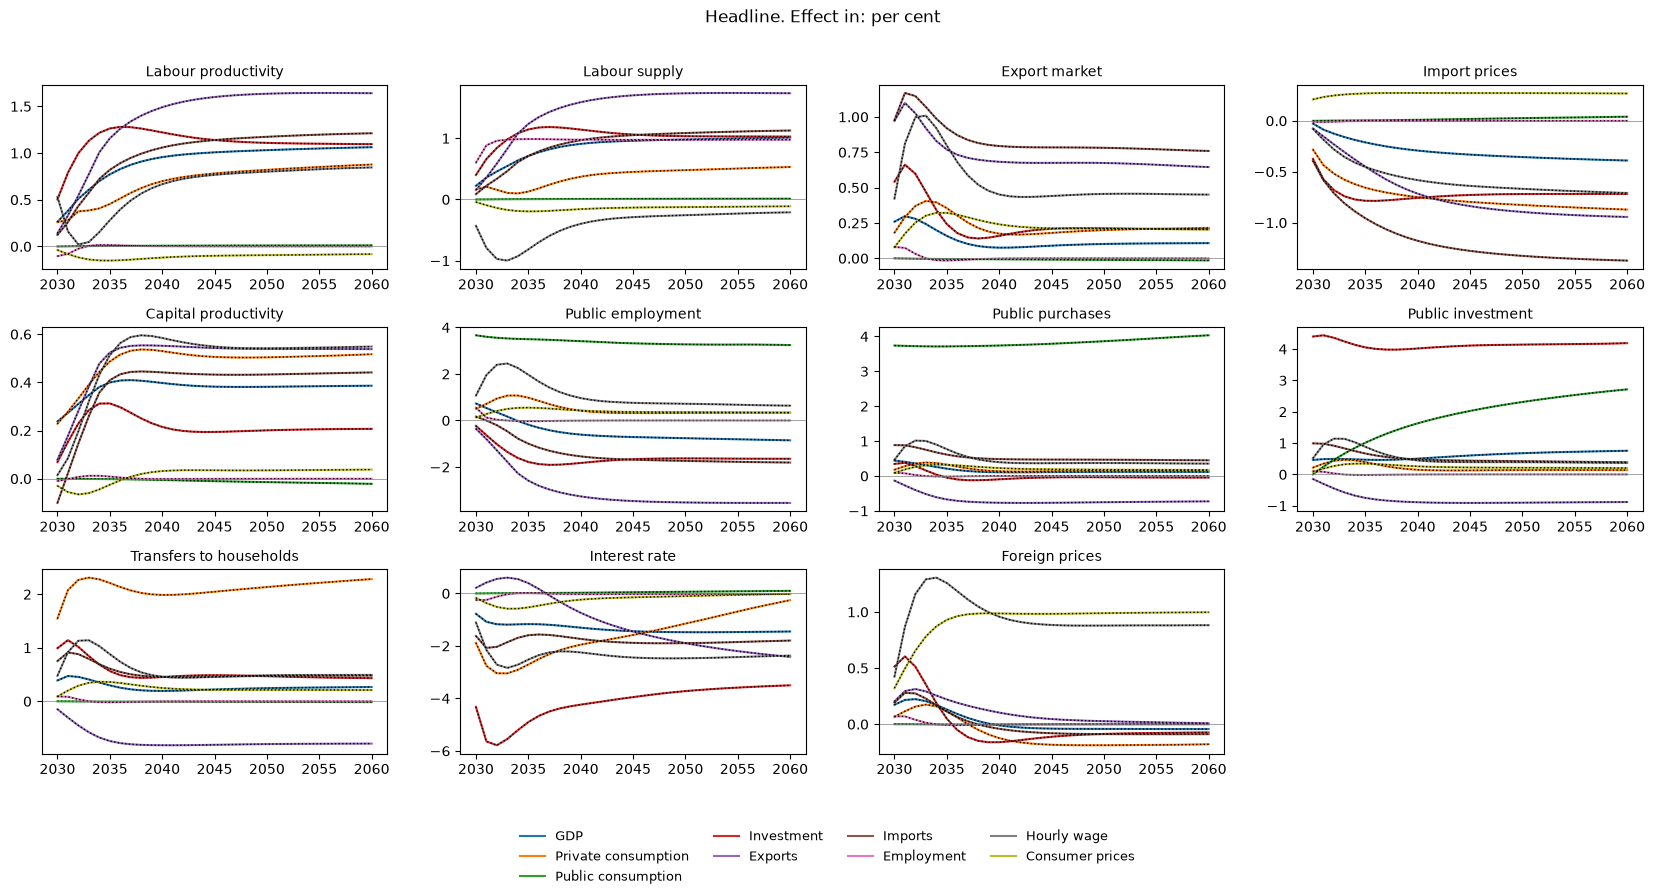

In [9]:
group_tables('Headline')
group_charts('Headline')

### Demand, contribution to GDP

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
GDP,0.26,0.22,0.26,-0.03,0.24,0.73,0.44,0.46,0.39,-0.77,0.17
Private consumption,0.12,0.08,0.08,-0.13,0.11,0.23,0.08,0.10,0.72,-0.87,0.03
Public consumption,-0.00,-0.00,-0.00,-0.00,-0.00,0.86,0.87,-0.00,-0.00,-0.00,-0.00
Investment,0.13,0.10,0.14,-0.09,0.02,-0.06,0.09,1.11,0.25,-1.09,0.13
Exports,0.10,0.10,0.66,-0.05,0.05,-0.24,-0.09,-0.10,-0.10,0.14,0.14
Imports,0.08,0.06,0.62,-0.25,-0.06,0.11,0.56,0.63,0.48,-1.03,0.12


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
GDP,0.77,0.71,0.16,-0.21,0.40,-0.18,0.21,0.47,0.30,-1.17,0.13
Private consumption,0.22,0.06,0.17,-0.32,0.24,0.48,0.16,0.19,1.08,-1.32,0.06
Public consumption,0.00,0.00,-0.00,0.00,-0.00,0.83,0.88,0.24,-0.00,0.00,-0.00
Investment,0.31,0.28,0.06,-0.19,0.08,-0.44,-0.01,1.00,0.14,-1.21,0.01
Exports,0.80,0.86,0.53,-0.31,0.36,-1.80,-0.47,-0.52,-0.52,0.27,0.15
Imports,0.55,0.48,0.62,-0.65,0.28,-0.67,0.41,0.45,0.41,-1.08,0.08


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
GDP,1.16,1.10,0.12,-0.44,0.39,-1.27,0.12,0.92,0.32,-1.04,-0.04
Private consumption,0.57,0.36,0.14,-0.55,0.31,0.20,0.10,0.07,1.42,1.97,-0.08
Public consumption,0.00,0.00,-0.01,0.03,-0.01,0.50,0.92,0.73,-0.01,0.06,0.00
Investment,0.28,0.26,0.05,-0.18,0.05,-0.44,-0.01,1.11,0.10,-0.79,-0.02
Exports,1.44,1.53,0.58,-0.84,0.45,-3.20,-0.62,-0.75,-0.74,-3.33,-0.01
Imports,1.11,1.03,0.68,-1.26,0.40,-1.61,0.40,0.34,0.49,-0.85,-0.08


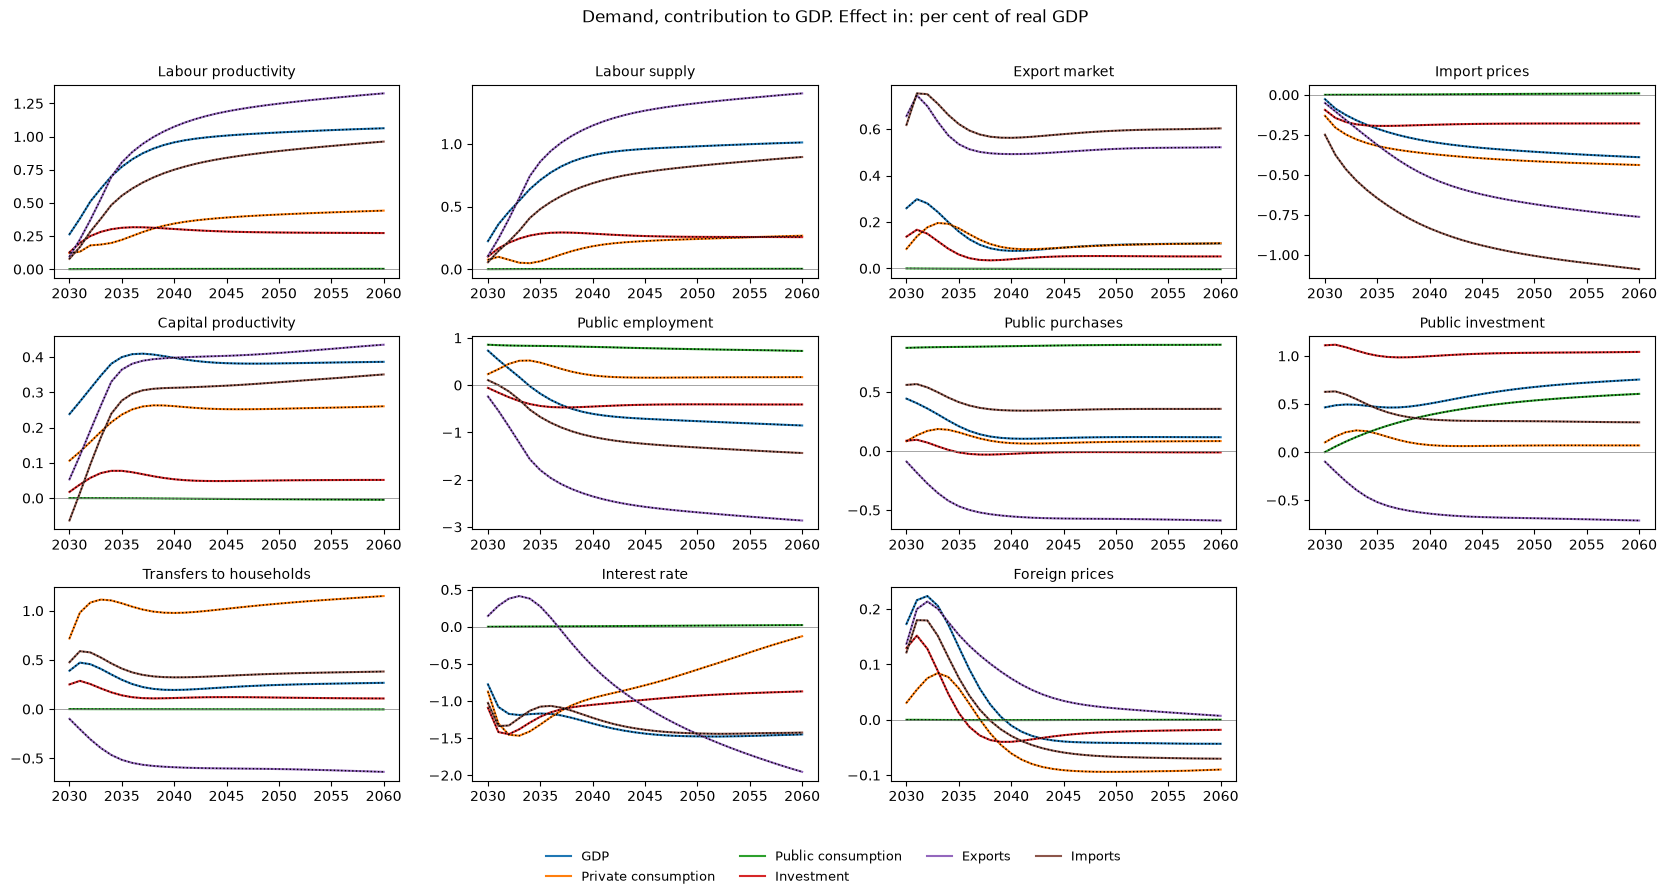

In [10]:
group_tables('Demand, contribution to GDP')
group_charts('Demand, contribution to GDP')

### Prices and wages

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
GDP deflator,-0.12,-0.12,0.17,-0.30,-0.04,0.36,0.17,0.22,0.19,-0.36,0.02
Consumer prices,-0.04,-0.04,0.08,0.21,-0.03,0.13,0.09,0.08,0.09,-0.17,0.32
Public consumption deflator,-0.28,-0.27,0.27,0.07,-0.00,0.73,0.23,0.34,0.31,-0.70,0.41
Investment deflator,-0.06,-0.06,0.06,0.23,-0.01,0.19,0.09,0.20,0.11,-0.12,0.32
Export deflator,-0.03,-0.03,0.07,0.21,-0.03,0.09,0.06,0.07,0.07,-0.12,0.46
Import deflator,-0.00,-0.00,0.00,1.00,-0.00,0.00,0.00,0.00,0.00,-0.00,1.00
"Output price, private sector",-0.04,-0.05,0.10,0.04,-0.04,0.14,0.10,0.10,0.11,-0.20,0.24
Hourly wage,0.53,-0.43,0.42,-0.08,0.01,1.07,0.46,0.52,0.48,-1.10,0.42
House price,0.40,0.17,0.43,-0.35,0.10,0.95,0.41,0.50,2.34,-5.44,0.61


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
GDP deflator,-0.32,-0.39,0.55,-0.24,0.03,1.10,0.53,0.63,0.62,-0.99,1.01
Consumer prices,-0.15,-0.20,0.32,0.27,-0.03,0.55,0.32,0.34,0.36,-0.53,0.93
Public consumption deflator,-0.48,-0.56,0.59,-0.11,0.28,1.50,0.43,0.66,0.66,-1.66,1.15
Investment deflator,-0.21,-0.26,0.32,0.32,0.01,0.72,0.34,0.49,0.39,-0.49,0.97
Export deflator,-0.11,-0.14,0.26,0.30,-0.04,0.40,0.23,0.27,0.27,-0.31,1.00
Import deflator,-0.00,-0.00,0.00,1.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,1.00
"Output price, private sector",-0.17,-0.22,0.38,0.13,-0.04,0.62,0.37,0.40,0.42,-0.56,0.98
Hourly wage,0.28,-0.82,0.80,-0.45,0.51,1.97,0.77,0.88,0.88,-2.52,1.26
House price,0.38,0.06,0.53,-0.41,0.26,1.15,0.49,0.61,2.25,-4.68,0.93


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
GDP deflator,-0.22,-0.28,0.34,-0.30,0.12,1.23,0.29,0.32,0.43,0.35,0.98
Consumer prices,-0.08,-0.12,0.21,0.27,0.04,0.39,0.17,0.21,0.23,0.35,1.00
Public consumption deflator,-0.13,-0.20,0.39,-0.42,0.40,1.50,-0.87,-0.39,0.48,-1.02,0.92
Investment deflator,-0.11,-0.15,0.20,0.27,0.07,0.53,0.20,0.34,0.29,0.35,0.98
Export deflator,-0.06,-0.08,0.16,0.28,-0.01,0.28,0.13,0.15,0.19,0.42,0.99
Import deflator,-0.00,-0.00,0.00,0.99,0.00,0.01,0.01,-0.00,0.00,-0.00,1.00
"Output price, private sector",-0.09,-0.14,0.23,0.11,0.02,0.45,0.22,0.24,0.32,0.52,0.99
Hourly wage,0.86,-0.21,0.48,-0.76,0.56,0.67,0.36,0.38,0.58,-1.56,0.88
House price,0.42,0.20,0.36,-0.34,0.25,0.65,0.28,0.41,1.72,0.48,0.91


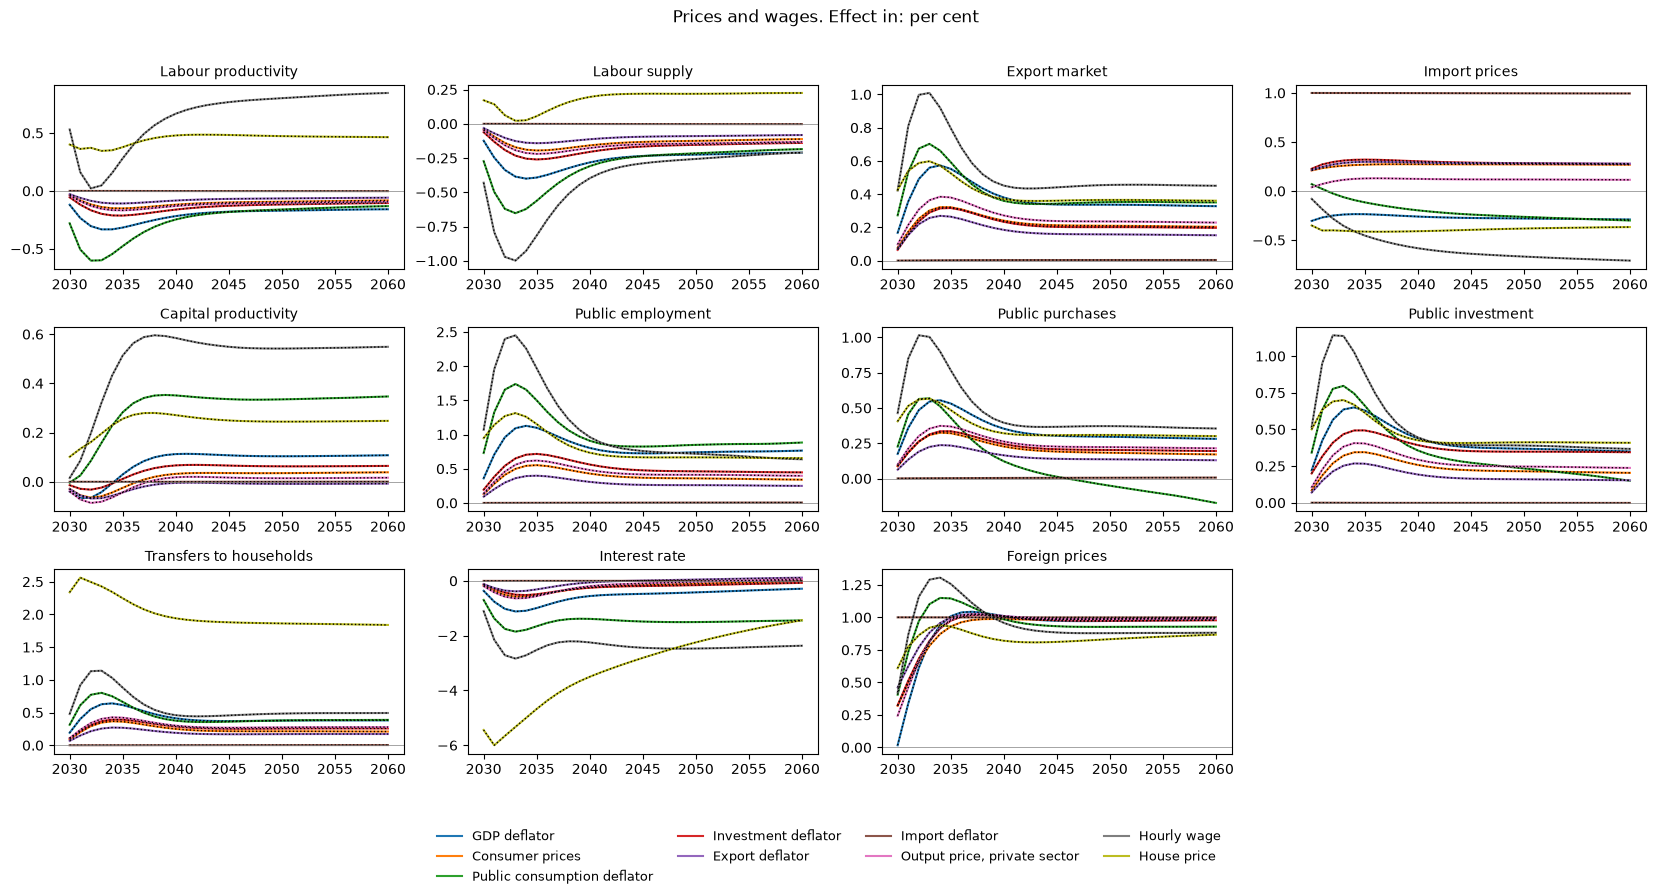

In [11]:
group_tables('Prices and wages')
group_charts('Prices and wages')

### Labour market

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
"Employment, 1000 persons",-3.30,19.09,2.56,-0.29,-0.30,17.54,2.98,3.27,2.90,-7.94,2.20
Hours worked,-0.10,0.62,0.08,-0.01,-0.01,0.50,0.09,0.10,0.09,-0.24,0.07
"Net labour force, 1000 persons",-2.14,-7.89,1.65,-0.19,-0.18,11.65,1.93,2.12,1.87,-4.66,1.43
"Net unemployment, 1000 persons",1.05,3.90,-0.81,0.09,0.09,-5.73,-0.94,-1.03,-0.91,2.26,-0.70
Net unemployment rate,0.03,0.13,-0.03,0.00,0.00,-0.18,-0.03,-0.03,-0.03,0.07,-0.02
Gross unemployment rate,0.04,0.16,-0.03,0.00,0.00,-0.24,-0.04,-0.04,-0.04,0.10,-0.03
Wage per efficiency unit,-0.47,-0.45,0.43,-0.08,0.01,1.09,0.47,0.52,0.48,-1.12,0.43
"User cost of labour, private sector",-1.60,-1.40,1.25,-0.12,-0.16,3.48,1.53,1.68,1.41,-3.04,1.07


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
"Employment, 1000 persons",0.47,31.47,-0.50,-0.05,0.29,-1.01,-0.51,-0.55,-0.60,0.53,-0.24
Hours worked,0.01,0.98,-0.02,-0.00,0.01,-0.03,-0.02,-0.02,-0.02,0.01,-0.01
"Net labour force, 1000 persons",0.31,0.25,-0.34,-0.04,0.19,-0.67,-0.34,-0.36,-0.40,0.83,-0.16
"Net unemployment, 1000 persons",-0.15,-0.12,0.16,0.02,-0.09,0.33,0.17,0.18,0.20,-0.41,0.08
Net unemployment rate,-0.00,-0.00,0.01,0.00,-0.00,0.01,0.01,0.01,0.01,-0.01,0.00
Gross unemployment rate,-0.01,-0.01,0.01,0.00,-0.00,0.01,0.01,0.01,0.01,-0.02,0.00
Wage per efficiency unit,-0.71,-0.83,0.80,-0.45,0.51,1.97,0.77,0.88,0.88,-2.52,1.26
"User cost of labour, private sector",-0.66,-0.79,0.74,-0.45,0.56,1.86,0.72,0.82,0.82,-2.26,1.24


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
"Employment, 1000 persons",0.00,34.64,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,-0.88,0.00
Hours worked,0.00,0.98,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,-0.03,0.00
"Net labour force, 1000 persons",0.00,-0.00,0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,-0.02,0.00
"Net unemployment, 1000 persons",-0.00,0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00
Net unemployment rate,-0.00,0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00
Gross unemployment rate,-0.00,0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00
Wage per efficiency unit,-0.14,-0.22,0.48,-0.76,0.56,0.67,0.36,0.38,0.58,-1.57,0.88
"User cost of labour, private sector",-0.14,-0.22,0.48,-0.76,0.56,0.67,0.36,0.38,0.58,-1.49,0.88


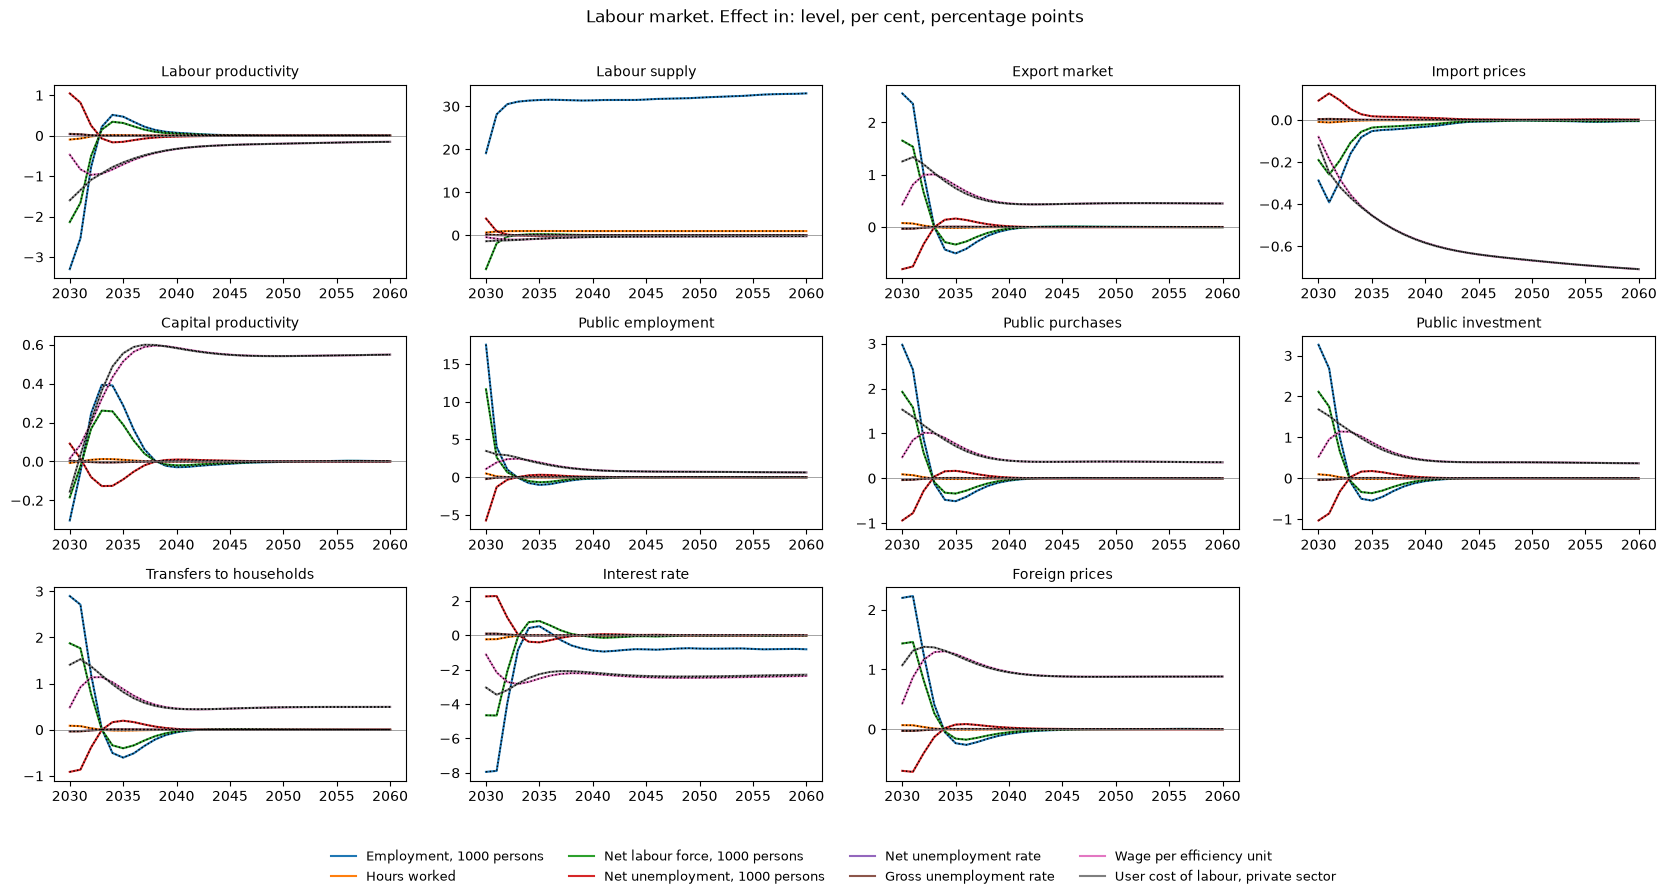

In [12]:
group_tables('Labour market')
group_charts('Labour market')

### Public finances

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Budget balance,0.20,0.12,0.13,-0.17,0.06,-0.68,-0.65,-0.74,-0.74,-0.77,0.07
Primary balance,0.20,0.12,0.13,-0.17,0.06,-0.68,-0.65,-0.74,-0.74,-0.92,0.07
Primary revenue,0.14,0.10,0.20,-0.15,0.05,0.36,0.34,0.36,0.34,-1.09,0.18
Primary expenditure,-0.06,-0.03,0.07,0.02,-0.00,1.04,1.00,1.09,1.08,-0.17,0.11
Direct taxes,0.10,0.08,0.13,-0.13,0.05,0.28,0.14,0.16,0.14,-0.75,0.11
Indirect taxes,0.03,0.02,0.06,-0.02,0.00,0.07,0.20,0.19,0.19,-0.32,0.06
"Public consumption, nominal",-0.07,-0.07,0.07,0.02,-0.00,1.09,0.98,0.08,0.08,-0.17,0.10
Social transfers,0.01,0.04,-0.01,0.00,0.00,-0.06,-0.01,-0.01,-0.01,0.02,-0.01
Net interest income,0.00,0.00,0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.15,0.00
Net financial wealth,0.26,0.19,0.17,-0.30,0.10,-0.79,-0.63,-0.71,-0.72,-1.82,0.15


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Budget balance,0.28,0.42,0.03,-0.18,0.08,-1.29,-0.92,-1.02,-0.93,-0.31,0.02
Primary balance,0.24,0.37,0.01,-0.15,0.06,-1.13,-0.79,-0.88,-0.80,-0.37,0.01
Primary revenue,0.19,0.07,0.34,-0.22,0.19,0.56,0.44,0.75,0.56,-1.26,0.55
Primary expenditure,-0.06,-0.30,0.33,-0.08,0.12,1.69,1.24,1.63,1.37,-0.89,0.54
Direct taxes,0.12,0.06,0.22,-0.17,0.13,0.39,0.19,0.22,0.23,-0.70,0.35
Indirect taxes,0.07,0.03,0.10,-0.06,0.05,0.12,0.23,0.22,0.31,-0.51,0.16
"Public consumption, nominal",-0.12,-0.14,0.15,-0.03,0.07,1.28,1.05,0.43,0.17,-0.42,0.29
Social transfers,0.06,-0.15,0.15,-0.05,0.05,0.39,0.15,0.17,0.17,-0.43,0.20
Net interest income,0.04,0.04,0.02,-0.03,0.01,-0.15,-0.12,-0.14,-0.12,0.06,0.02
Net financial wealth,1.27,1.67,0.56,-1.10,0.42,-5.58,-4.28,-4.78,-4.30,-3.95,0.48


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Budget balance,2.03,3.08,0.40,-1.31,0.47,-8.64,-6.19,-6.66,-6.13,27.81,0.35
Primary balance,0.27,0.40,0.05,-0.17,0.07,-1.04,-0.74,-0.80,-0.71,1.86,0.06
Primary revenue,0.43,0.33,0.23,-0.36,0.24,0.14,0.29,1.13,0.50,1.44,0.48
Primary expenditure,0.16,-0.07,0.18,-0.19,0.18,1.19,1.04,1.92,1.21,-0.42,0.42
Direct taxes,0.29,0.24,0.15,-0.27,0.17,0.12,0.10,0.11,0.21,1.09,0.30
Indirect taxes,0.13,0.09,0.06,-0.09,0.06,-0.01,0.18,0.17,0.27,0.26,0.13
"Public consumption, nominal",-0.03,-0.05,0.09,-0.08,0.09,1.06,0.96,0.85,0.11,-0.20,0.24
Social transfers,0.18,-0.04,0.07,-0.11,0.08,0.13,0.05,0.05,0.08,-0.22,0.13
Net interest income,1.76,2.67,0.35,-1.14,0.40,-7.60,-5.45,-5.87,-5.42,25.95,0.30
Net financial wealth,43.55,66.33,8.68,-28.28,9.97,-188.30,-134.93,-145.35,-134.23,463.60,7.35


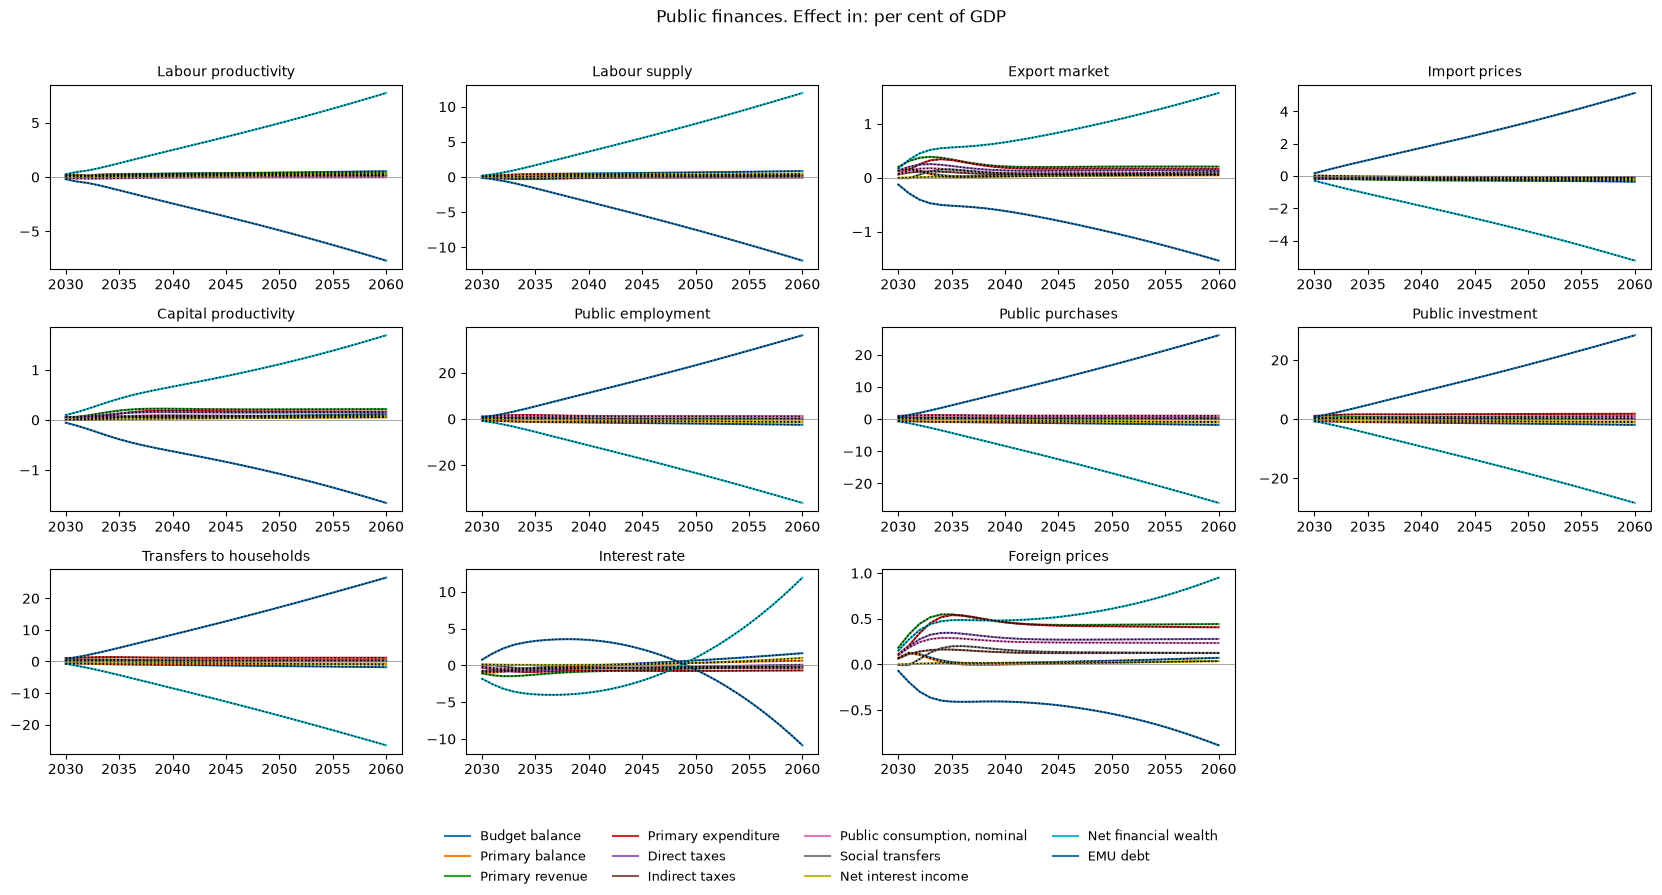

In [13]:
group_tables('Public finances')
group_charts('Public finances')

### Balance of payments

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Current account,-0.00,0.03,0.09,-0.28,0.09,-0.30,-0.60,-0.67,-0.52,1.50,-0.30
Trade balance,-0.00,0.03,0.09,-0.28,0.09,-0.28,-0.59,-0.66,-0.52,1.06,-0.29
"Exports, nominal",0.08,0.08,0.69,0.09,0.03,-0.17,-0.05,-0.05,-0.05,0.06,0.44
"Imports, nominal",0.08,0.05,0.60,0.37,-0.06,0.10,0.55,0.61,0.46,-1.00,0.74
Foreigners' net interest income,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.44,-0.00
Foreigners' net financial wealth in DK,0.23,0.18,0.07,-0.16,0.05,-0.07,0.66,0.77,0.61,-5.16,0.58


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Current account,0.23,0.35,0.12,-0.19,0.07,-1.07,-0.82,-0.91,-0.87,1.37,0.11
Trade balance,0.18,0.28,0.11,-0.12,0.06,-0.84,-0.69,-0.75,-0.71,1.07,0.11
"Exports, nominal",0.70,0.73,0.69,-0.10,0.32,-1.47,-0.30,-0.32,-0.32,0.05,0.82
"Imports, nominal",0.52,0.45,0.59,0.02,0.26,-0.63,0.39,0.42,0.39,-1.01,0.71
Foreigners' net interest income,-0.05,-0.06,-0.02,0.07,-0.02,0.19,0.12,0.14,0.15,-0.34,-0.01
Foreigners' net financial wealth in DK,-0.08,-0.60,-0.38,0.40,-0.17,2.91,4.03,4.48,4.00,-14.71,0.86


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Current account,2.09,3.13,0.43,-1.40,0.50,-8.76,-6.19,-6.65,-6.26,27.45,0.43
Trade balance,0.28,0.41,0.05,-0.20,0.06,-1.23,-0.77,-0.81,-0.90,-1.85,0.06
"Exports, nominal",1.19,1.25,0.61,-0.52,0.38,-2.54,-0.44,-0.53,-0.49,-2.55,0.72
"Imports, nominal",0.91,0.84,0.56,-0.32,0.33,-1.31,0.33,0.28,0.41,-0.70,0.66
Foreigners' net interest income,-1.82,-2.73,-0.39,1.21,-0.46,7.50,5.41,5.83,5.33,-29.50,-0.39
Foreigners' net financial wealth in DK,-44.50,-66.75,-9.67,28.74,-11.13,182.25,133.60,143.99,128.78,-545.46,-9.01


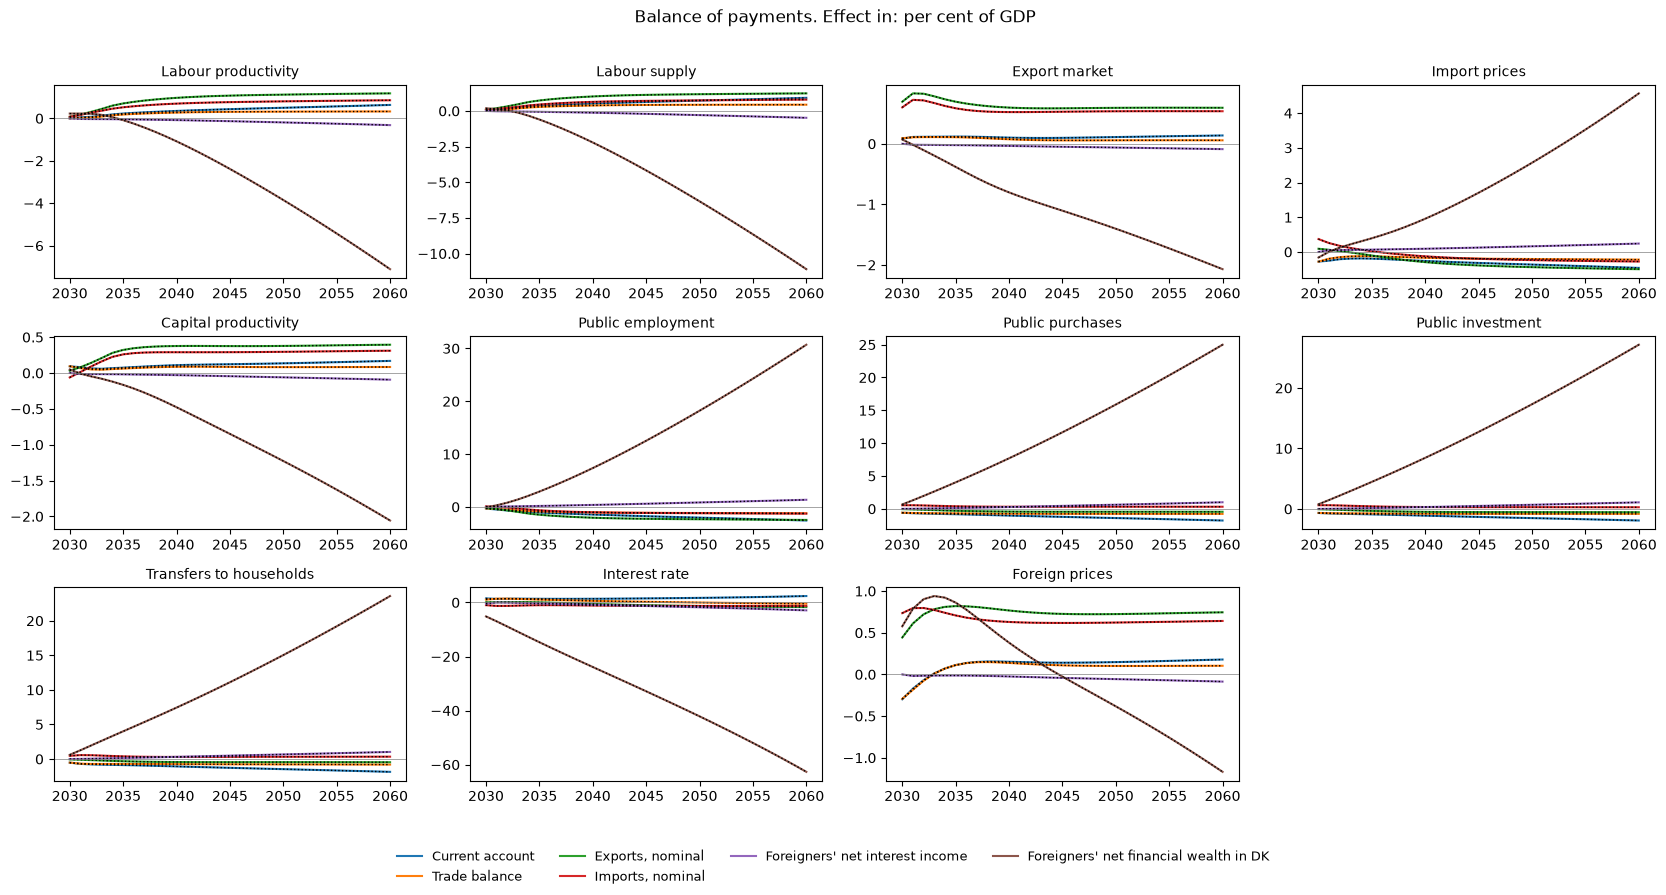

In [14]:
group_tables('Balance of payments')
group_charts('Balance of payments')

### Net lending by sector

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Public sector,0.20,0.12,0.13,-0.17,0.06,-0.68,-0.65,-0.74,-0.74,-0.77,0.07
Households,-0.02,-0.01,-0.02,0.10,-0.08,0.20,0.02,0.02,0.23,1.98,-0.11
Firms,-0.18,-0.08,-0.03,-0.21,0.12,0.19,0.04,0.05,-0.01,0.29,-0.26
Abroad,0.00,-0.03,-0.09,0.28,-0.09,0.30,0.60,0.67,0.52,-1.50,0.30


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Public sector,0.28,0.42,0.03,-0.18,0.08,-1.29,-0.92,-1.02,-0.93,-0.31,0.02
Households,-0.05,-0.06,0.05,0.04,0.01,0.21,0.06,0.07,0.01,1.30,0.07
Firms,0.00,0.00,0.04,-0.05,-0.01,0.01,0.03,0.04,0.04,0.37,0.02
Abroad,-0.23,-0.35,-0.12,0.19,-0.07,1.07,0.82,0.91,0.87,-1.37,-0.11


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Public sector,2.03,3.08,0.40,-1.31,0.47,-8.64,-6.19,-6.66,-6.13,27.81,0.35
Households,0.00,0.00,0.01,-0.01,0.01,-0.00,0.00,0.02,-0.12,-0.62,0.02
Firms,0.06,0.06,0.02,-0.09,0.02,-0.12,-0.01,-0.01,-0.01,0.26,0.06
Abroad,-2.09,-3.13,-0.43,1.40,-0.50,8.76,6.19,6.65,6.26,-27.45,-0.43


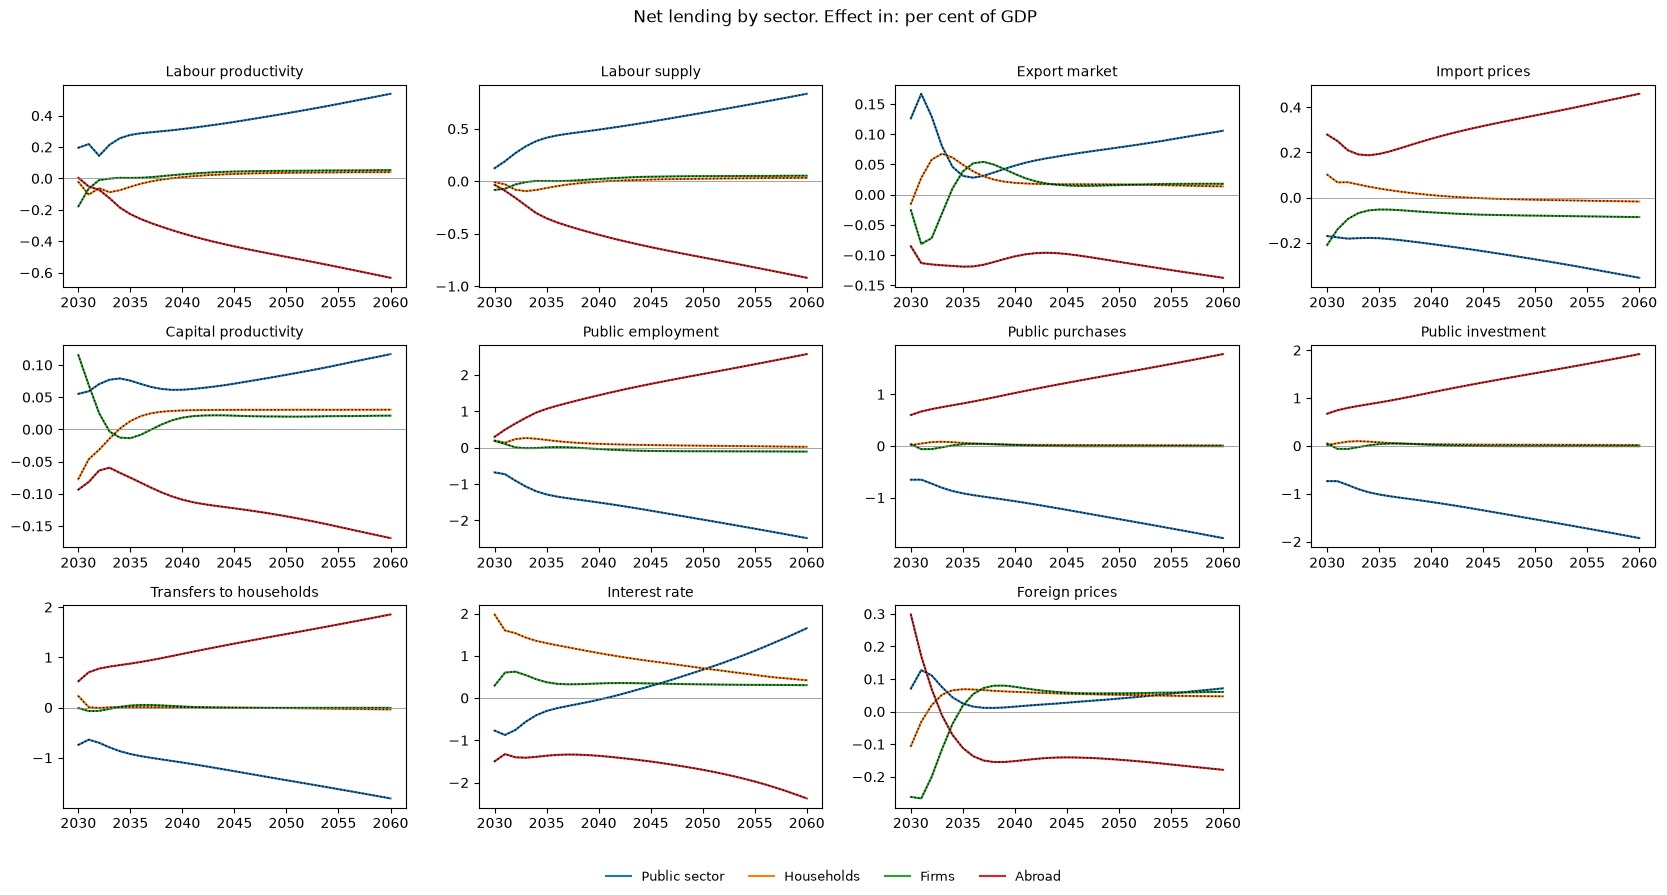

In [15]:
group_tables('Net lending by sector')
group_charts('Net lending by sector')

### Value added by sector

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Total,0.26,0.23,0.24,0.01,0.27,0.80,0.31,0.36,0.24,-0.54,0.17
Private sector,0.33,0.29,0.30,0.02,0.33,-0.41,0.39,0.46,0.31,-0.67,0.21
Manufacturing,0.32,0.30,0.42,0.08,0.31,-0.59,0.03,0.24,-0.01,-0.17,0.27
Services,0.36,0.31,0.34,0.00,0.19,-0.40,0.64,0.41,0.46,-0.79,0.22
Construction,0.67,0.55,0.25,-0.09,0.12,-0.58,0.40,2.70,0.85,-2.98,0.35
Housing,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00
Public sector,0.00,-0.00,0.00,0.00,0.00,5.55,-0.00,0.00,0.00,0.00,0.00


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Total,0.79,0.76,0.12,-0.12,0.41,-0.21,0.05,0.39,0.10,-0.92,0.14
Private sector,1.00,0.95,0.15,-0.16,0.51,-1.66,0.06,0.08,0.12,-1.15,0.17
Manufacturing,1.28,1.35,0.20,-0.23,0.61,-2.77,-0.62,-0.43,-0.68,-0.56,0.27
Services,1.03,0.96,0.14,-0.12,0.38,-1.59,0.34,0.00,0.31,-0.95,0.18
Construction,1.31,1.18,0.03,-0.26,0.13,-1.75,0.12,2.77,0.69,-3.60,0.05
Housing,0.15,0.08,0.08,-0.14,1.04,0.15,0.07,0.03,0.55,-1.27,0.07
Public sector,0.00,0.00,-0.00,0.00,-0.00,5.37,-0.00,1.53,-0.00,0.01,-0.00


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Total,1.19,1.17,0.08,-0.29,0.39,-1.44,-0.07,0.95,0.08,-1.43,-0.02
Private sector,1.39,1.36,0.10,-0.37,0.50,-2.41,-0.08,-0.12,0.10,-1.86,-0.04
Manufacturing,1.73,1.87,0.14,-0.68,0.65,-4.02,-0.83,-0.71,-1.07,-4.92,-0.00
Services,1.37,1.31,0.03,-0.16,0.32,-2.22,0.23,-0.18,0.27,-0.60,-0.04
Construction,1.05,0.98,0.00,-0.07,0.03,-1.44,0.19,3.33,0.54,-1.09,-0.02
Housing,0.80,0.53,0.16,-0.64,1.19,0.20,0.11,-0.08,2.02,-0.31,-0.10
Public sector,0.01,0.01,-0.02,0.06,-0.03,4.70,-0.02,6.12,-0.02,0.14,0.00


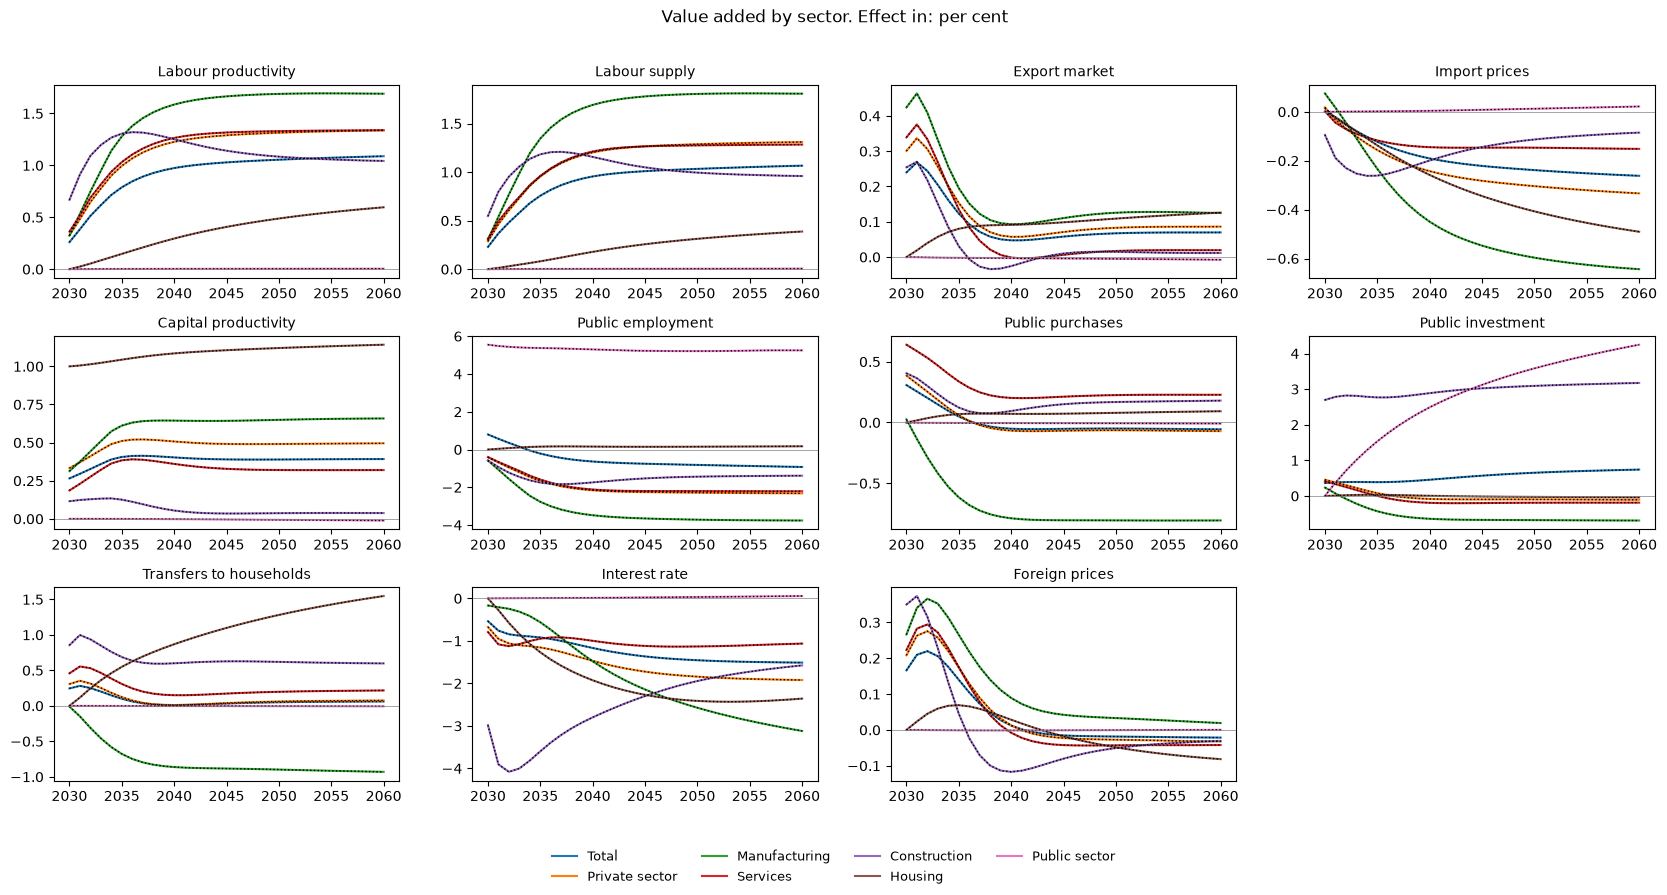

In [16]:
group_tables('Value added by sector')
group_charts('Value added by sector')

### Investment and capital

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Private equipment investment,0.48,0.43,0.73,-0.39,0.09,-0.58,0.42,0.45,0.51,-3.91,0.60
Private structures investment,0.76,0.55,0.52,-0.52,0.07,0.06,0.42,0.24,2.01,-6.89,0.65
Housing investment,0.60,0.32,0.47,-0.52,0.14,0.94,0.43,0.27,2.83,-6.68,0.58
Public investment,0.00,-0.00,0.00,0.00,0.00,0.00,0.00,25.87,0.00,0.00,0.00
"Equipment capital, private",0.10,0.08,0.14,-0.08,0.02,-0.11,0.08,0.09,0.10,-0.77,0.12
"Structures capital, private",0.03,0.02,0.02,-0.02,0.00,0.00,0.02,0.01,0.09,-0.30,0.03


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Private equipment investment,1.48,1.44,0.33,-0.90,0.46,-2.71,-0.10,-0.18,-0.07,-4.71,0.07
Private structures investment,1.51,1.24,0.23,-0.97,0.25,-1.37,0.04,-0.27,1.59,-7.41,0.02
Housing investment,0.93,0.55,0.22,-0.82,0.30,0.38,0.16,-0.04,2.49,-5.54,-0.01
Public investment,0.00,0.00,-0.00,0.01,-0.00,-0.00,0.00,28.61,-0.00,0.00,0.01
"Equipment capital, private",0.89,0.85,0.44,-0.56,0.28,-1.51,0.08,0.07,0.14,-3.67,0.27
"Structures capital, private",0.29,0.23,0.10,-0.20,0.04,-0.17,0.06,-0.00,0.46,-1.85,0.09


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Private equipment investment,1.47,1.46,0.32,-0.98,0.31,-2.79,-0.09,-0.17,-0.00,-4.89,-0.07
Private structures investment,1.07,0.90,0.18,-0.71,0.13,-0.90,0.04,-0.18,1.28,-2.17,-0.09
Housing investment,0.82,0.56,0.16,-0.66,0.20,0.19,0.11,-0.09,2.09,0.26,-0.10
Public investment,0.00,0.00,-0.00,0.01,-0.00,-0.00,0.00,29.95,-0.00,0.00,0.01
"Equipment capital, private",1.47,1.46,0.40,-0.92,0.31,-2.79,-0.11,-0.17,-0.01,-5.09,-0.07
"Structures capital, private",0.99,0.79,0.17,-0.68,0.14,-0.61,0.06,-0.15,1.44,-1.97,-0.09


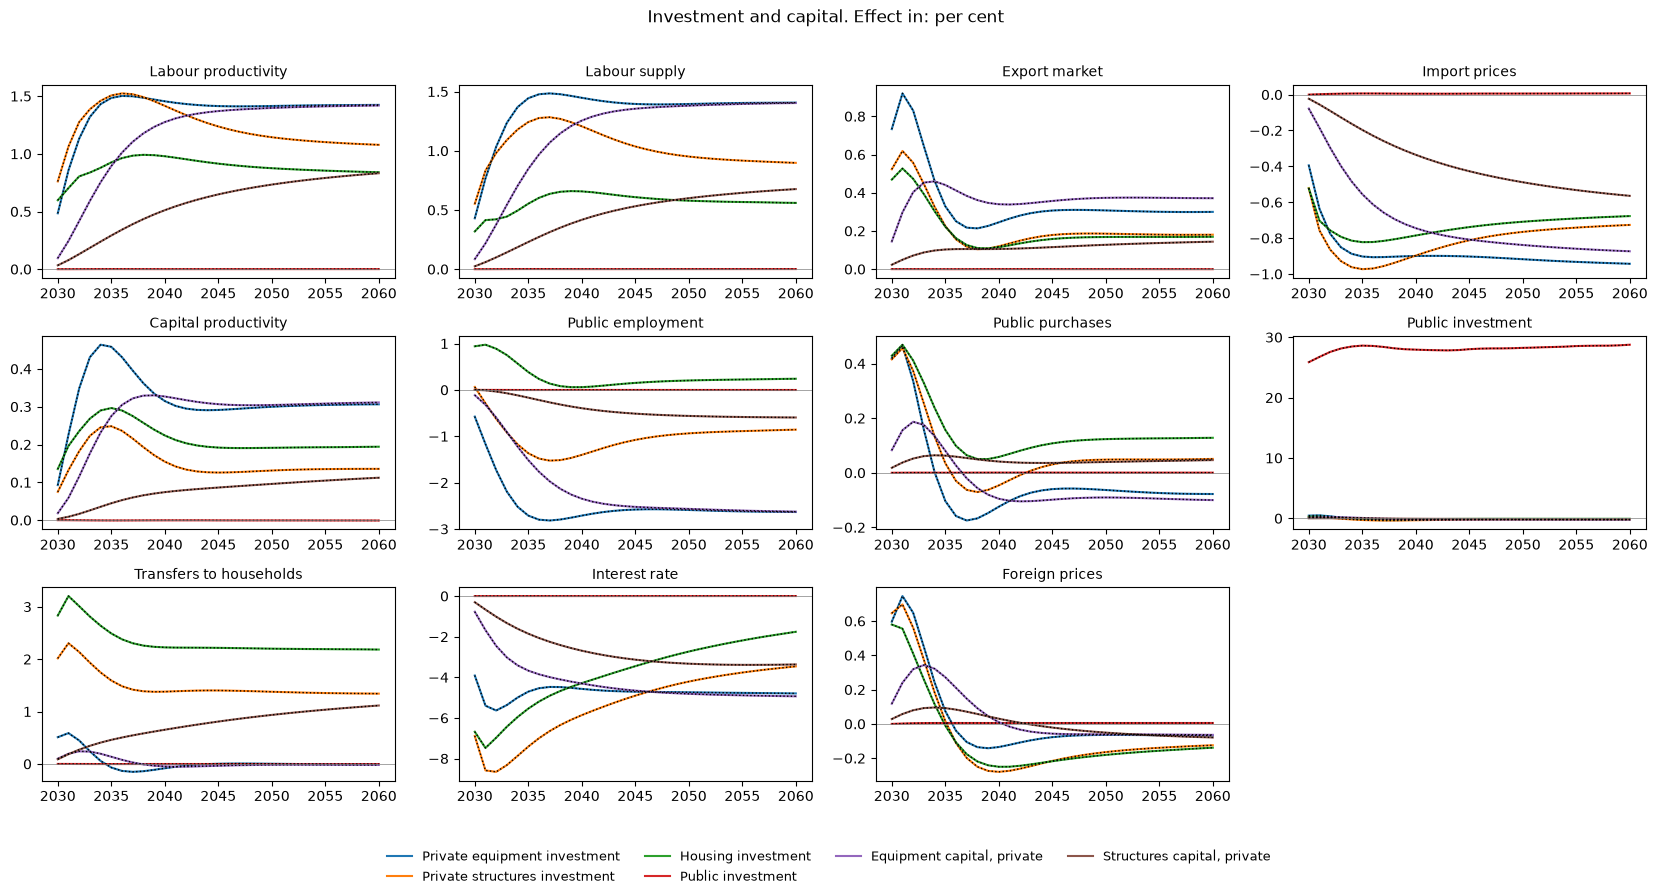

In [17]:
group_tables('Investment and capital')
group_charts('Investment and capital')

### Private production

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Production,0.18,0.15,0.71,-0.20,0.04,0.00,0.70,0.89,0.64,-1.43,0.31
Intermediates,0.07,0.05,1.02,-0.37,-0.17,0.32,0.97,1.25,0.90,-2.04,0.40
"Labour, efficiency units",1.56,1.32,-0.17,0.03,0.00,-2.65,-0.19,-0.21,-0.20,0.49,-0.17
Unit cost,-0.16,-0.16,0.37,0.21,-0.25,0.48,0.40,0.41,0.39,-0.82,0.59
Output price,-0.04,-0.05,0.10,0.04,-0.04,0.14,0.10,0.10,0.11,-0.20,0.24
"Export price, direct exports",-0.03,-0.04,0.09,0.05,-0.04,0.11,0.08,0.08,0.08,-0.15,0.35


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Production,0.96,0.90,0.38,-0.48,0.49,-1.51,0.15,0.27,0.23,-1.22,0.20
Intermediates,0.95,0.87,0.53,-0.74,0.46,-1.42,0.23,0.43,0.31,-1.27,0.22
"Labour, efficiency units",1.36,1.34,0.02,0.00,-0.01,-2.39,0.02,0.02,0.02,0.00,0.01
Unit cost,-0.17,-0.23,0.38,0.18,-0.03,0.64,0.36,0.40,0.42,-0.46,1.00
Output price,-0.17,-0.22,0.38,0.13,-0.04,0.62,0.37,0.40,0.42,-0.56,0.98
"Export price, direct exports",-0.13,-0.17,0.32,0.16,-0.05,0.48,0.28,0.32,0.33,-0.38,1.00


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Production,1.39,1.35,0.29,-0.77,0.47,-2.39,-0.04,0.02,0.14,-1.79,-0.06
Intermediates,1.38,1.34,0.40,-1.10,0.45,-2.38,0.01,0.14,0.15,-1.69,-0.08
"Labour, efficiency units",1.41,1.39,0.00,-0.00,0.00,-2.47,-0.00,0.00,0.00,0.04,0.00
Unit cost,-0.09,-0.14,0.24,0.16,0.01,0.44,0.21,0.24,0.31,0.56,0.97
Output price,-0.09,-0.14,0.23,0.11,0.02,0.45,0.22,0.24,0.32,0.52,0.99
"Export price, direct exports",-0.07,-0.11,0.20,0.15,-0.01,0.35,0.16,0.20,0.25,0.50,0.99


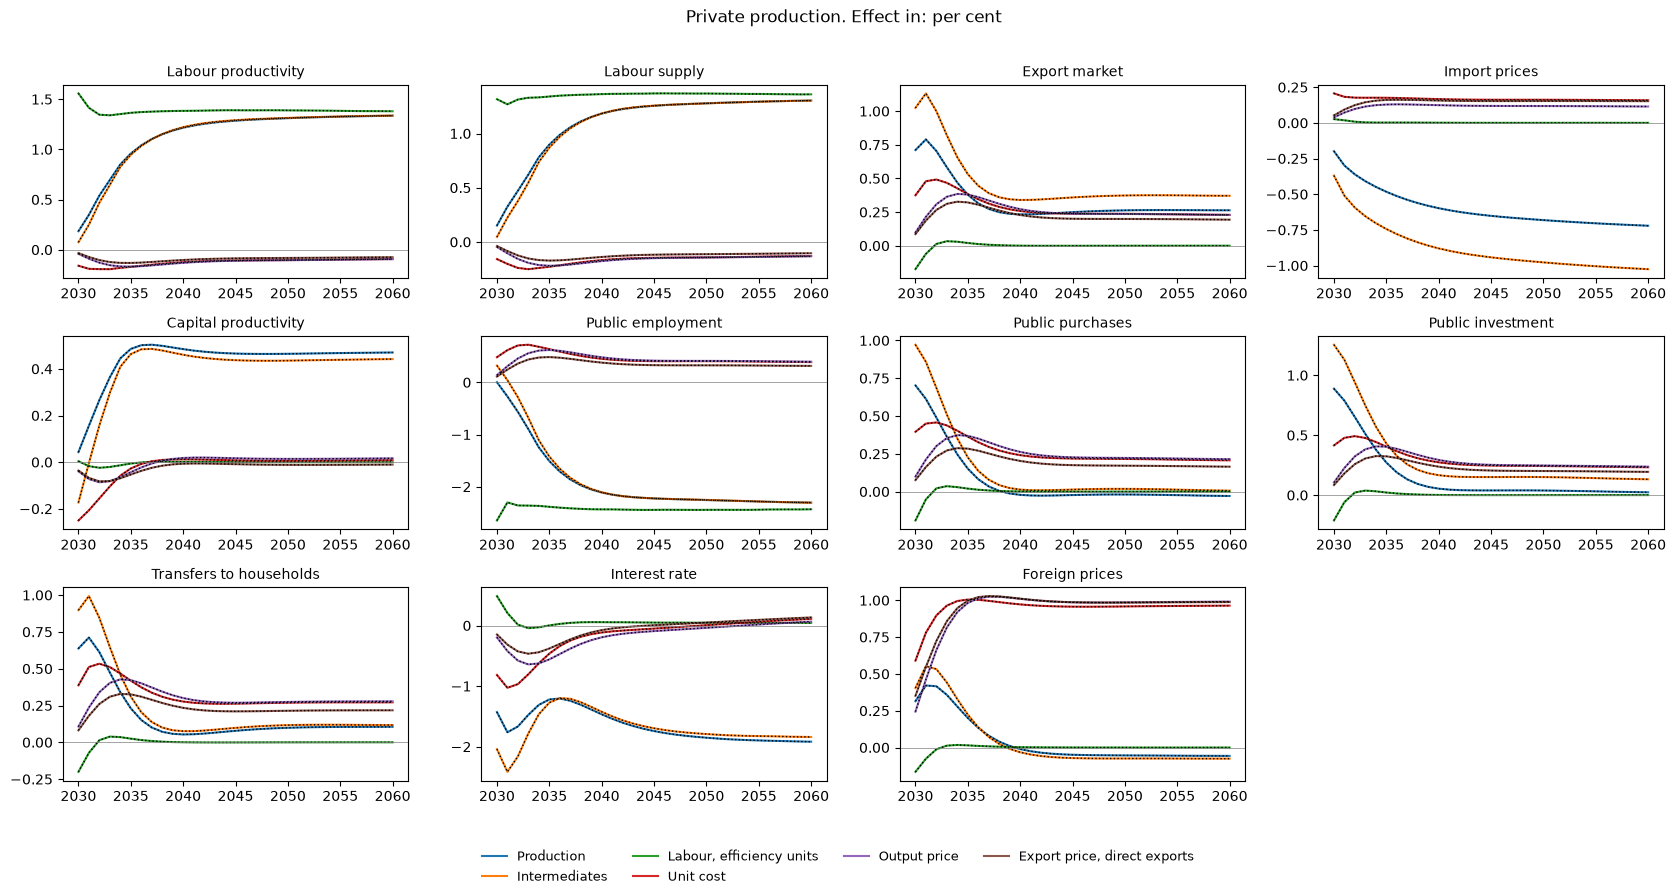

In [18]:
group_tables('Private production')
group_charts('Private production')

### Exports by group

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Goods excl. energy,0.16,0.18,0.91,-0.13,0.10,-0.42,-0.17,-0.20,-0.19,0.23,0.31
Services excl. sea transport,0.19,0.22,0.88,-0.05,0.07,-0.53,-0.24,-0.25,-0.26,0.48,0.30
Sea transport,0.08,0.08,1.12,-0.00,0.04,-0.15,-0.01,-0.00,-0.00,0.01,-0.00
Energy,0.04,0.08,0.84,-0.14,0.29,-0.33,-0.18,-0.25,-0.36,0.18,0.18
Tourism,0.17,0.19,0.92,-0.17,0.07,-0.47,-0.21,-0.21,-0.23,0.41,0.25


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Goods excl. energy,1.26,1.36,0.46,-0.78,0.63,-2.93,-0.87,-1.01,-0.97,0.36,0.33
Services excl. sea transport,1.46,1.62,0.28,-0.28,0.41,-3.57,-1.24,-1.32,-1.36,1.80,0.31
Sea transport,0.85,0.83,1.52,-0.05,0.40,-1.50,-0.02,-0.01,0.00,-0.41,0.03
Energy,0.61,0.82,0.16,-0.73,1.65,-2.41,-0.89,-1.28,-1.75,-1.28,-0.15
Tourism,1.34,1.47,0.47,-0.77,0.45,-3.23,-1.05,-1.11,-1.16,1.40,0.24


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Goods excl. energy,1.80,1.96,0.37,-1.51,0.66,-4.26,-0.98,-1.18,-1.25,-5.16,0.01
Services excl. sea transport,1.90,2.12,0.08,-0.49,0.13,-4.77,-1.21,-1.43,-1.61,-3.47,0.03
Sea transport,1.39,1.36,1.47,-0.37,0.50,-2.41,-0.08,-0.12,0.10,-1.86,-0.04
Energy,1.86,2.04,0.37,-2.40,2.34,-4.48,-0.99,-1.59,-1.32,-16.04,-0.86
Tourism,1.84,2.00,0.32,-1.36,0.26,-4.48,-1.01,-1.24,-1.22,-3.43,-0.03


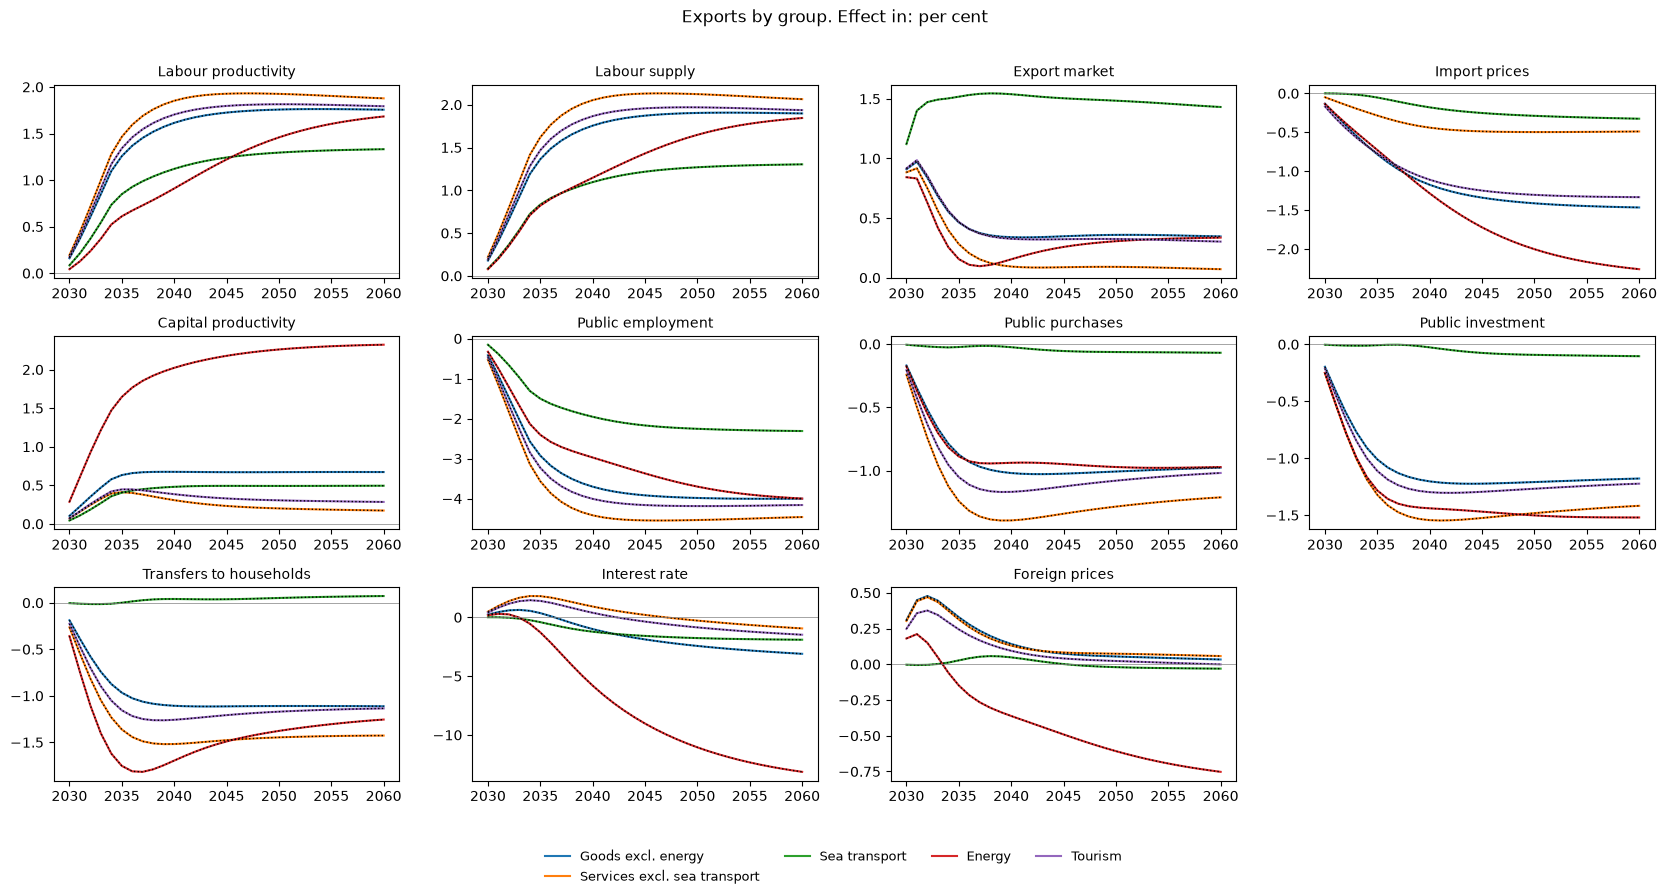

In [19]:
group_tables('Exports by group')
group_charts('Exports by group')

### Households

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Income after tax excl. capital income,0.30,0.20,0.30,-0.11,0.02,0.86,0.33,0.37,2.47,-1.15,0.31
Wage income before tax,0.43,0.20,0.50,-0.09,0.01,1.57,0.55,0.61,0.56,-1.34,0.49
Wealth incl. housing and pension,0.35,0.24,0.31,-0.47,0.14,0.21,0.24,0.31,1.24,-4.87,0.47
"Wealth excl. housing, mortgages and pension",0.33,0.31,0.24,-0.59,0.17,-0.35,0.13,0.18,0.50,-4.85,0.38
Housing wealth,0.42,0.18,0.44,-0.37,0.11,0.98,0.42,0.51,2.44,-5.67,0.63
House price,0.40,0.17,0.43,-0.35,0.10,0.95,0.41,0.50,2.34,-5.44,0.61


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Income after tax excl. capital income,0.29,-0.14,0.74,-0.40,0.40,1.84,0.72,0.83,2.91,-2.17,1.11
Wage income before tax,0.30,0.18,0.78,-0.45,0.52,1.94,0.75,0.87,0.86,-2.51,1.25
Wealth incl. housing and pension,0.30,0.14,0.43,-0.47,0.20,0.60,0.37,0.45,1.43,-2.46,0.65
"Wealth excl. housing, mortgages and pension",0.23,0.15,0.44,-0.53,0.15,0.36,0.35,0.44,1.26,-2.26,0.58
Housing wealth,0.53,0.14,0.60,-0.55,0.30,1.29,0.55,0.64,2.79,-5.87,0.99
House price,0.38,0.06,0.53,-0.41,0.26,1.15,0.49,0.61,2.25,-4.68,0.93


,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Income after tax excl. capital income,0.92,0.49,0.46,-0.72,0.52,0.75,0.35,0.37,2.72,2.44,0.85
Wage income before tax,0.86,0.78,0.48,-0.76,0.56,0.67,0.36,0.38,0.58,-1.59,0.88
Wealth incl. housing and pension,0.81,0.56,0.44,-0.66,0.40,0.73,0.35,0.34,2.27,11.05,0.86
"Wealth excl. housing, mortgages and pension",0.61,0.39,0.39,-0.49,0.30,0.70,0.32,0.32,2.66,13.11,0.87
Housing wealth,1.24,0.74,0.52,-0.99,0.44,0.86,0.40,0.33,3.82,0.08,0.80
House price,0.42,0.20,0.36,-0.34,0.25,0.65,0.28,0.41,1.72,0.48,0.91


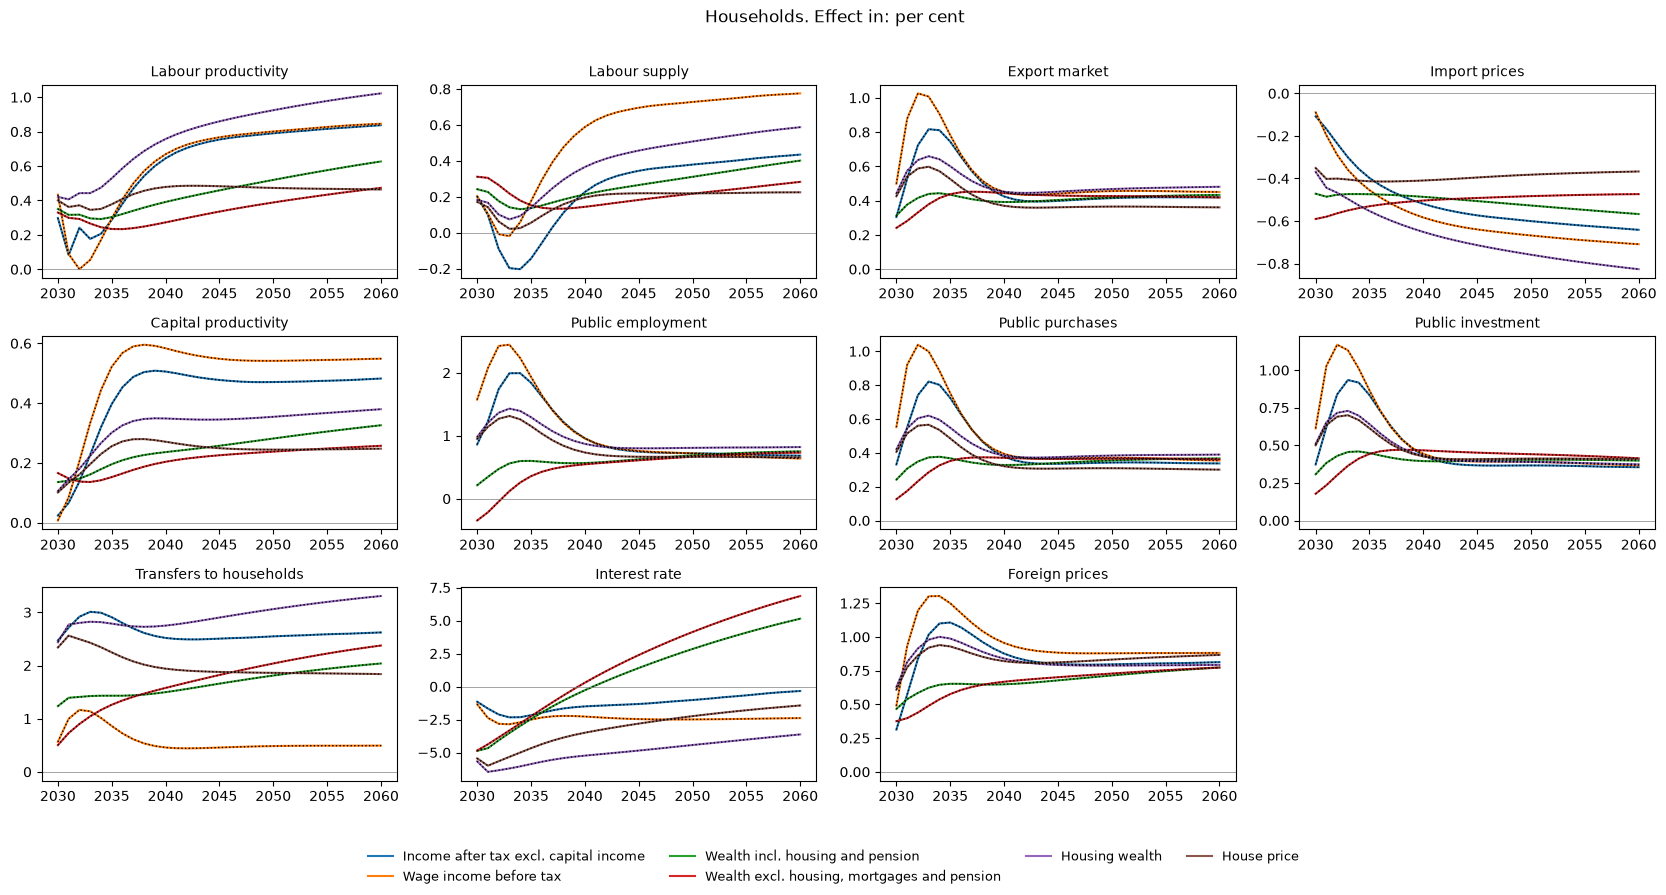

In [20]:
group_tables('Households')
group_charts('Households')

## 7. One variable across the shocks

`one_variable` shows any variable the model determines for all the shocks. The whole solutions are in memory
(`solutions`).

In [21]:
def one_variable(variable, years=(2030, 2031, 2032, 2035, 2040, 2050, 2129), pct=True):
    years = list(years)
    out = {}
    for n in solved_shocks:
        x = solutions[n][variable]
        b = baseline.loc[years, variable]
        out[label[n]] = 100 * (x.loc[years] / b - 1) if pct else x.loc[years] - b
    print(variable, ':', mmakro.var_description.get(variable, ''), '-', 'per cent from the baseline' if pct else 'difference from the baseline')
    return pd.DataFrame(out).T.round(3)

one_variable('QBNP')

QBNP : BNP, Kilde: ADAM[fY] (MAKRO qBNP) - per cent from the baseline


year,2030,2031,2032,2035,2040,2050,2129
Labour productivity,0.263,0.382,0.511,0.772,0.956,1.031,1.155
Labour supply,0.223,0.358,0.458,0.711,0.909,0.981,1.097
Export market,0.259,0.298,0.280,0.159,0.076,0.102,0.122
Import prices,-0.027,-0.086,-0.126,-0.212,-0.292,-0.356,-0.439
Capital productivity,0.238,0.274,0.310,0.400,0.398,0.382,0.391
Public employment,0.731,0.534,0.350,-0.181,-0.608,-0.762,-1.274
Public purchases,0.443,0.404,0.360,0.210,0.106,0.118,0.115
Public investment,0.465,0.486,0.495,0.470,0.504,0.677,0.923
Transfers to households,0.390,0.473,0.456,0.298,0.194,0.246,0.324
Interest rate,-0.775,-1.081,-1.174,-1.169,-1.304,-1.477,-1.043


## 8. Save the model with all the solutions

`data\makro26_shocks.pcimz` is written: the model, the baseline and every solved shock as kept solutions
(`keep=True`), for analysing the results without solving anything. It holds the variable descriptions and the
variable groups of section 2. Each kept solution is a whole dataframe like the baseline: the changed inputs, the
first-year switch and everything the model determines.

`data\makro26_baseline.pcimz`, the input of this notebook, is not written here.

**Solve options.** A dump saves the model's solve options, and these change with every solve (they are
sticky). So the cell sets them first to the ones a loaded model should start from: the stacked Newton, exact
derivatives and the normal-equations factorizer as a dict. `ljit` is left out: the compiled code belongs to the
working directory, and a program started elsewhere would compile for 20 minutes before its first solve. A
notebook adds `ljit=True` to its first call.

The model was loaded with `straight=True` (from the file), and the dump stores that, so the file loads fast
again with only the file name (`model.modelload(file)`; `straight=False` in the call gives the ordinary load).

`derivatives=True` stores the expressions for the derivatives of the model with the file. The first stacked
solve of a session then takes them from the model instead of working them out again, which saves 2 of its 5
minutes.

In [22]:
DATA = r'C:\mfmodeller_raw\makro\makro26\data'
print('straight:', mmakro.straight, '| sets of derivative expressions on the model:', len(mmakro.diff_expressions))

mmakro.keep_solutions = {'Baseline': baseline}
for n in solved_shocks:
    mmakro.keep_solutions[label[n]] = solutions[n]
mmakro.basedf = mmakro.lastdf = baseline
mmakro.current_per = baseline.loc[first:last].index
mmakro.oldkwargs = dict(solver='newtonstack_ng', forcenum=False, factorizer=dream_shocks.FACTORIZER, silent=1)
print('Solve options saved with the model:', mmakro.oldkwargs)

mmakro.model_description = "MAKRO 2026-September (DREAM) in ModelFlow, baseline and DREAM's standard shocks 2030-2129"
mmakro.modeldump(DATA + r'\makro26_shocks.pcimz', keep=True, large=True, derivatives=True)

straight: True | sets of derivative expressions on the model: 1
Solve options saved with the model: {'solver': 'newtonstack_ng', 'forcenum': False, 'factorizer': {'method': 'normal', 'iparm': {1: 13}, 'refine_tol': 1e-06}, 'silent': 1}


Model dumped (feather/zip): C:\mfmodeller_raw\makro\makro26\data\makro26_shocks.pcimz


**Using the files.** The cell below loads the file with the solutions again, as another notebook would, and
shows the kept solutions with ModelFlow's own tools: `keep_solutions` is a dictionary of dataframes, and
`keep_plot` draws a variable for all of them.

Feather/zip file read: C:\mfmodeller_raw\makro\makro26\data\makro26_shocks.pcimz


Model: MAKRO 2026-September (DREAM) in ModelFlow, baseline and DREAM's standard shocks 2030-2129
loaded in 5.8 seconds, straight: True
solve options: {'solver': 'newtonstack_ng', 'forcenum': False, 'factorizer': {'method': 'normal', 'iparm': {'1': 13}, 'refine_tol': 1e-06}, 'silent': 1}
['Baseline', 'Labour productivity', 'Labour supply', 'Export market', 'Import prices', 'Capital productivity', 'Public employment', 'Public purchases', 'Public investment', 'Transfers to households', 'Interest rate', 'Foreign prices']


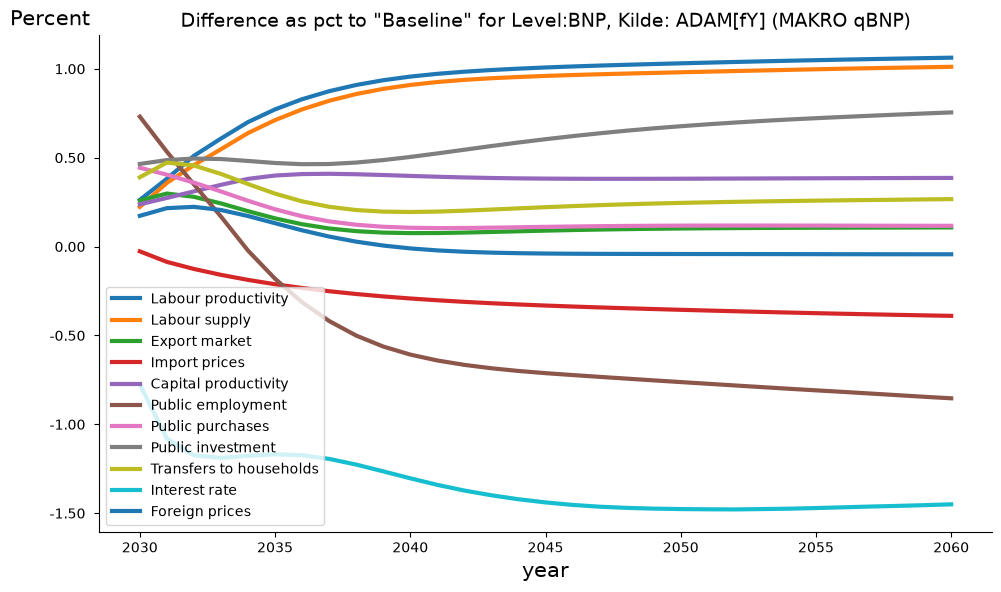

In [23]:
t0 = time.time()
mshocks, base2 = model.modelload(DATA + r'\makro26_shocks.pcimz')
print(f'loaded in {time.time() - t0:.1f} seconds, straight: {mshocks.straight}')
print('solve options:', mshocks.oldkwargs)
print(list(mshocks.keep_solutions))
with mshocks.set_smpl(2030, 2060):
    figs = mshocks.keep_plot('QBNP', diffpct=True, legend=True, showfig=True)

In [24]:
# the effect of every kept solution on a variable group, in one year
year = 2035
pd.DataFrame({name: makro_groups.effect(df, mshocks.keep_solutions['Baseline'], 'Public finances', [year])[year]
              for name, df in mshocks.keep_solutions.items() if name != 'Baseline'}).round(2)

,Labour productivity,Labour supply,Export market,Import prices,Capital productivity,Public employment,Public purchases,Public investment,Transfers to households,Interest rate,Foreign prices
Budget balance,0.28,0.42,0.03,-0.18,0.08,-1.29,-0.92,-1.02,-0.93,-0.31,0.02
Primary balance,0.24,0.37,0.01,-0.15,0.06,-1.13,-0.79,-0.88,-0.80,-0.37,0.01
Primary revenue,0.19,0.07,0.34,-0.22,0.19,0.56,0.44,0.75,0.56,-1.26,0.55
Primary expenditure,-0.06,-0.30,0.33,-0.08,0.12,1.69,1.24,1.63,1.37,-0.89,0.54
Direct taxes,0.12,0.06,0.22,-0.17,0.13,0.39,0.19,0.22,0.23,-0.70,0.35
Indirect taxes,0.07,0.03,0.10,-0.06,0.05,0.12,0.23,0.22,0.31,-0.51,0.16
"Public consumption, nominal",-0.12,-0.14,0.15,-0.03,0.07,1.28,1.05,0.43,0.17,-0.42,0.29
Social transfers,0.06,-0.15,0.15,-0.05,0.05,0.39,0.15,0.17,0.17,-0.43,0.20
Net interest income,0.04,0.04,0.02,-0.03,0.01,-0.15,-0.12,-0.14,-0.12,0.06,0.02
Net financial wealth,1.27,1.67,0.56,-1.10,0.42,-5.58,-4.28,-4.78,-4.30,-3.95,0.48
